### **Stage 0 — Setup: Imports, Configuration & PySpark Session Factory**


**Cell 0.1 — Import libraries and display settings** 


In [1]:
import os, sys, time, json, decimal, warnings, subprocess

if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")
if hasattr(sys.stderr, "reconfigure"):
    sys.stderr.reconfigure(encoding="utf-8", errors="replace")

warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import yaml

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:.4f}".format)
os.environ["MPLCONFIGDIR"] = os.path.join(
    os.getcwd(), "outputs", ".mplconfig"
)
os.makedirs(os.environ["MPLCONFIGDIR"], exist_ok=True)

import matplotlib
matplotlib.use("Agg")

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
try:
    from IPython.display import display
except (ImportError, NameError):
    def display(x):
        if hasattr(x, "to_string"):
            print(x.to_string())
        else:
            print(x)

**Cell 0.2 — Set the project location**

In [2]:
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(".."))

PROJECT_ROOT = os.getcwd()
print(f"[DIR] Working directory: {PROJECT_ROOT}")

[DIR] Working directory: c:\1_BAU\Master_bau_first_semester\intro_big_data\final_project


**Cell 0.3 — Load configuration**

In [3]:
with open("config.yaml", "r") as _f:
    CFG = yaml.safe_load(_f)

RAW_CSV = CFG["paths"]["raw_csv"]
BRONZE_PATH = CFG["paths"]["bronze_parquet"]
SILVER_PATH = CFG["paths"]["silver_parquet"]
GOLD_PATH = CFG["paths"]["gold_parquet"]

OUTPUTS_DIR = CFG["paths"]["outputs_dir"]
FIGURES_DIR = CFG["paths"]["figures_dir"]
MODELS_DIR = CFG["paths"]["models_dir"]
SEED = CFG["project"]["random_seed"]

**Cell 0.4 — Create folders and show paths**

In [4]:
for _d in [
    OUTPUTS_DIR,
    FIGURES_DIR,
    MODELS_DIR,
    os.path.join(OUTPUTS_DIR, "sql_analytics"),
    "data/raw",
    "data/bronze",
    "data/silver",
    "data/gold",
]:
    os.makedirs(_d, exist_ok=True)

print(f"[FILE] Raw CSV     : {RAW_CSV}")
print(f"[BRONZE] Bronze    : {BRONZE_PATH}")
print(f"[SILVER] Silver    : {SILVER_PATH}")
print(f"[GOLD] Gold        : {GOLD_PATH}")
print(f"[CHART] Outputs   : {OUTPUTS_DIR}")
print(f"[SEED] Random Seed : {SEED}")

[FILE] Raw CSV     : data/raw/paysim.csv
[BRONZE] Bronze    : data/bronze/paysim_bronze.parquet
[SILVER] Silver    : data/silver/paysim_silver.parquet
[GOLD] Gold        : data/gold/paysim_gold.parquet
[CHART] Outputs   : outputs
[SEED] Random Seed : 42


**Cell 0.5 — Start Spark and define feature sets**

In [5]:
sys.path.insert(0, PROJECT_ROOT)
from src.spark_utils import get_spark_session

spark = get_spark_session(app_name="FraudDetection_Pipeline")
spark.sparkContext.setLogLevel("ERROR")

F0_COLS = [
    "txn_hour",
    "txn_day",
    "log_amount",
    "origin_balance_before",
    "destination_balance_before",
    "type_index",
]
F1_COLS = F0_COLS + [
    "amount_to_origin_ratio",
    "insufficient_origin_balance",
    "dest_zero_balance_flag",
    "is_transfer",
    "is_cash_out",
]
print("\n[PASS] Stage 0 complete — All imports loaded, PySpark factory ready.")


[PASS] Stage 0 complete — All imports loaded, PySpark factory ready.


### **Stage 1 — Environment & System Verification**


**Cell 1.1 — Start verification and check Python**

In [6]:
results = []
results.append((
    "S1-T01",
    "Python >= 3.9",
    "PASS" if sys.version_info >= (3, 9) else "FAIL",
    sys.version.split()[0],
))

**Cell 1.2 — Check Java and PySpark**

In [7]:
try:
    jv = subprocess.check_output(
        ["java", "-version"],
        stderr=subprocess.STDOUT,
    ).decode().split("\n")[0]
    results.append((
        "S1-T02", "Java Runtime", "PASS", jv.strip()
    ))
except Exception as e:
    results.append((
        "S1-T02", "Java Runtime", "FAIL", str(e)[:60]
    ))
try:
    import pyspark

    results.append((
        "S1-T03", "PySpark Package", "PASS",
        f"v{pyspark.__version__}",
    ))
except ImportError:
    results.append((
        "S1-T03", "PySpark Package", "FAIL", "Not installed"
    ))

**Cell 1.3 — Test Spark execution**

In [8]:
try:
    test_df = spark.createDataFrame(
        [(1, "cluster_sanity_check")],
        ["id", "val"],
    )
    cnt_val = test_df.count()
    sc = spark.sparkContext
    results.append((
        "S1-T04",
        "Spark Execution Test",
        "PASS" if cnt_val == 1 else "FAIL",
        f"Rows: {cnt_val}, default parallelism: "
        f"{sc.defaultParallelism}, Spark {spark.version}",
    ))
except Exception as e:
    results.append((
        "S1-T04", "Spark Execution Test", "FAIL", str(e)[:60]
    ))

**Cell 1.4 — Check configuration, dataset, and folders**

In [9]:
results.append((
    "S1-T05",
    "Config File Exists",
    "PASS" if os.path.exists("config.yaml") else "FAIL",
    "config.yaml",
))
if os.path.exists(RAW_CSV):
    sz_mb = os.path.getsize(RAW_CSV) / (1024 * 1024)
    results.append((
        "S1-T06",
        "Raw Dataset Exists",
        "PASS",
        f"{RAW_CSV} ({sz_mb:.1f} MB)",
    ))
else:
    results.append((
        "S1-T06",
        "Raw Dataset Exists",
        "FAIL",
        f"Missing {RAW_CSV}",
    ))
all_dirs = all(
    os.path.isdir(d)
    for d in [OUTPUTS_DIR, FIGURES_DIR, MODELS_DIR]
)
results.append((
    "S1-T07",
    "Output Directories Ready",
    "PASS" if all_dirs else "FAIL",
    "outputs, models, figures",
))

**Cell 1.5 — Check Imbalanced-learn and TabPFN**

In [10]:
try:
    import imblearn
    results.append((
        "S1-T08",
        "Imbalance-Learn Package",
        "PASS",
        f"v{imblearn.__version__}",
    ))
except ImportError:
    results.append((
        "S1-T08",
        "Imbalance-Learn Package",
        "FAIL",
        "Not installed",
    ))

try:
    import tabpfn
    results.append((
        "S1-T09",
        "TabPFN Package",
        "PASS",
        f"v{tabpfn.__version__}",
    ))
except ImportError:
    results.append((
        "S1-T09",
        "TabPFN Package",
        "FAIL",
        "Not installed",
    ))

**Cell 1.6 — Display verification results**

In [11]:
print(
    f"[CHECK] Running {len(results)} automated "
    "system & component sanity checks:"
)
for tid, name, status, detail in results:
    print(f"  [{status}] {tid}: {name} ({detail})")
all_pass = all(status == "PASS" for _, _, status, _ in results)
if all_pass:
    print(
        f"All {len(results)} system checks PASSED. "
        "Runtime environment verified."
    )
else:
    failed_count = sum(
        1 for _, _, status, _ in results
        if status == "FAIL"
    )
    print(f"Warning: {failed_count} checks failed.")

[CHECK] Running 9 automated system & component sanity checks:
  [PASS] S1-T01: Python >= 3.9 (3.11.0)
  [PASS] S1-T02: Java Runtime (openjdk version "11" 2018-09-25)
  [PASS] S1-T03: PySpark Package (v3.5.9)
  [PASS] S1-T04: Spark Execution Test (Rows: 1, default parallelism: 8, Spark 3.5.9)
  [PASS] S1-T05: Config File Exists (config.yaml)
  [PASS] S1-T06: Raw Dataset Exists (data/raw/paysim.csv (470.7 MB))
  [PASS] S1-T07: Output Directories Ready (outputs, models, figures)
  [PASS] S1-T08: Imbalance-Learn Package (v0.14.2)
  [PASS] S1-T09: TabPFN Package (v9.2.0)
All 9 system checks PASSED. Runtime environment verified.


### **Stage 2a — Bronze Layer: Schema Enforcement & Parquet Ingestion**


**Cell 2a.1 — Define the dataset schema**

In [12]:
from pyspark.sql.types import (
    StructType, StructField, StringType, IntegerType, DoubleType
)
from pyspark.sql import functions as F
schema = StructType([
    StructField("step",           IntegerType(), True),
    StructField("type",           StringType(),  True),
    StructField("amount",         DoubleType(),  True),
    StructField("nameOrig",       StringType(),  True),
    StructField("oldbalanceOrg",  DoubleType(),  True),
    StructField("newbalanceOrig", DoubleType(),  True),
    StructField("nameDest",       StringType(),  True),
    StructField("oldbalanceDest", DoubleType(),  True),
    StructField("newbalanceDest", DoubleType(),  True),
    StructField("isFraud",        IntegerType(), True),
    StructField("isFlaggedFraud", IntegerType(), True),
])

**Cell 2a.2 — Read CSV and write Bronze Parquet**

In [13]:
print(f"[INGEST] Reading raw CSV with explicit schema: {RAW_CSV}")
t0 = time.perf_counter()
df_raw = (
    spark.read
    .option("header", "true")
    .schema(schema)
    .csv(RAW_CSV)
)
print("[WRITE] Writing Bronze Parquet (8 partitions, snappy compression) ...")
(
    df_raw.repartition(8)
    .write.mode("overwrite")
    .option("compression", "snappy")
    .parquet(BRONZE_PATH)
)
elapsed_ingest = time.perf_counter() - t0
print(f"[METRIC] Ingestion completed in {elapsed_ingest:.2f} seconds.")

[INGEST] Reading raw CSV with explicit schema: data/raw/paysim.csv
[WRITE] Writing Bronze Parquet (8 partitions, snappy compression) ...
[METRIC] Ingestion completed in 7.42 seconds.


**Cell 2a.3 — Read and inspect the Bronze dataset**

In [14]:
df_bronze = spark.read.parquet(BRONZE_PATH)
bronze_count = df_bronze.count()
bronze_cols = len(df_bronze.columns)
print(f"[COUNT] Total Ingested Transactions: {bronze_count:,}")
print("[SCHEMA] Bronze Schema:")
df_bronze.printSchema()

[COUNT] Total Ingested Transactions: 6,362,620
[SCHEMA] Bronze Schema:
root
 |-- step: integer (nullable = true)
 |-- type: string (nullable = true)
 |-- amount: double (nullable = true)
 |-- nameOrig: string (nullable = true)
 |-- oldbalanceOrg: double (nullable = true)
 |-- newbalanceOrig: double (nullable = true)
 |-- nameDest: string (nullable = true)
 |-- oldbalanceDest: double (nullable = true)
 |-- newbalanceDest: double (nullable = true)
 |-- isFraud: integer (nullable = true)
 |-- isFlaggedFraud: integer (nullable = true)



**Cell 2a.4 — Validate schema and transaction count**

In [15]:
assert df_bronze.schema == schema, (
    f"Bronze schema mismatch.\n"
    f"Expected: {schema.simpleString()}\n"
    f"Actual:   {df_bronze.schema.simpleString()}"
)
print(
    f"[PASS] S2-T01: Bronze schema matches the expected schema "
    f"({bronze_cols} typed columns)"
)
assert bronze_count == 6_362_620, (
    f"Unexpected record count: expected 6,362,620, "
    f"got {bronze_count:,}"
)
print(
    f"[PASS] S2-T02: Exact record count validated "
    f"({bronze_count:,} rows)"
)

[PASS] S2-T01: Bronze schema matches the expected schema (11 typed columns)
[PASS] S2-T02: Exact record count validated (6,362,620 rows)


**Cell 2a.5 — Save ingestion metadata**

In [16]:
ingest_meta = {
    "raw_csv_path": RAW_CSV,
    "raw_csv_size_mb": round(
        os.path.getsize(RAW_CSV) / (1024 * 1024), 2
    ),
    "bronze_parquet_path": BRONZE_PATH,
    "record_count": bronze_count,
    "column_count": bronze_cols,
    "ingestion_duration_seconds": round(elapsed_ingest, 2),
    "partitions": 8,
    "compression": "snappy",
}
metadata_path = os.path.join(OUTPUTS_DIR, "ingest_metadata.json")
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(ingest_meta, f, indent=2)
print(
    f"[PASS] S2-T03: Ingestion metadata persisted to {metadata_path}"
)

[PASS] S2-T03: Ingestion metadata persisted to outputs\ingest_metadata.json


### **Stage 2b — Silver Layer: Data Quality Audit & Spark SQL Analytics**


**Cell 2b.1 — Check data quality**

In [17]:
total_rows = bronze_count
null_exprs = [
    F.sum(
        F.when(
            F.col(c).isNull()
            | (
                F.isnan(F.col(c))
                if t in ["double", "float"]
                else F.lit(False)
            ),
            1,
        ).otherwise(0)
    ).alias(c)
    for c, t in df_bronze.dtypes
]
null_counts = df_bronze.select(null_exprs).collect()[0].asDict()
dup_rows = total_rows - df_bronze.dropDuplicates().count()
neg_amounts = df_bronze.filter(F.col("amount") < 0).count()
zero_amounts = df_bronze.filter(F.col("amount") == 0).count()

**Cell 2b.2 — Calculate and display class distribution**

In [18]:
fraud_counts = {
    int(r["isFraud"]): r["count"]
    for r in df_bronze.groupBy("isFraud").count().collect()
}
fraud_count = fraud_counts.get(1, 0)
legit_count = fraud_counts.get(0, 0)
fraud_rate_pct = round(fraud_count / total_rows * 100, 4)
legit_rate_pct = legit_count / total_rows * 100
class_df = pd.DataFrame([
    {
        "Class Label": "Legitimate (0)",
        "Transactions": f"{legit_count:,}",
        "Proportion": f"{legit_rate_pct:.4f}%",
    },
    {
        "Class Label": "Fraud (1)",
        "Transactions": f"{fraud_count:,}",
        "Proportion": f"{fraud_rate_pct:.4f}%",
    },
])
print("\n[WEIGHT] Class Distribution:")
display(class_df)


[WEIGHT] Class Distribution:


,Class Label,Transactions,Proportion
0,Legitimate (0),"6,354,407",99.8709%
1,Fraud (1),"8,213",0.1291%


**Cell 2b.3 — Save the data quality report**

In [19]:
dq_report = {
    "total_records": total_rows,
    "null_counts": null_counts,
    "duplicate_transactions_found": dup_rows,
    "negative_amounts_count": neg_amounts,
    "zero_amounts_count": zero_amounts,
    "class_distribution": {
        "legitimate_count": legit_count,
        "fraud_count": fraud_count,
        "fraud_percentage": fraud_rate_pct,
    },
}

dq_path = os.path.join(OUTPUTS_DIR, "data_quality_report.json")
with open(dq_path, "w", encoding="utf-8") as f:
    json.dump(dq_report, f, indent=2)

print(f"\n[SAVE] Data Quality Report saved -> {dq_path}")


[SAVE] Data Quality Report saved -> outputs\data_quality_report.json


**Cell 2b.4 — Create and save the class distribution chart**

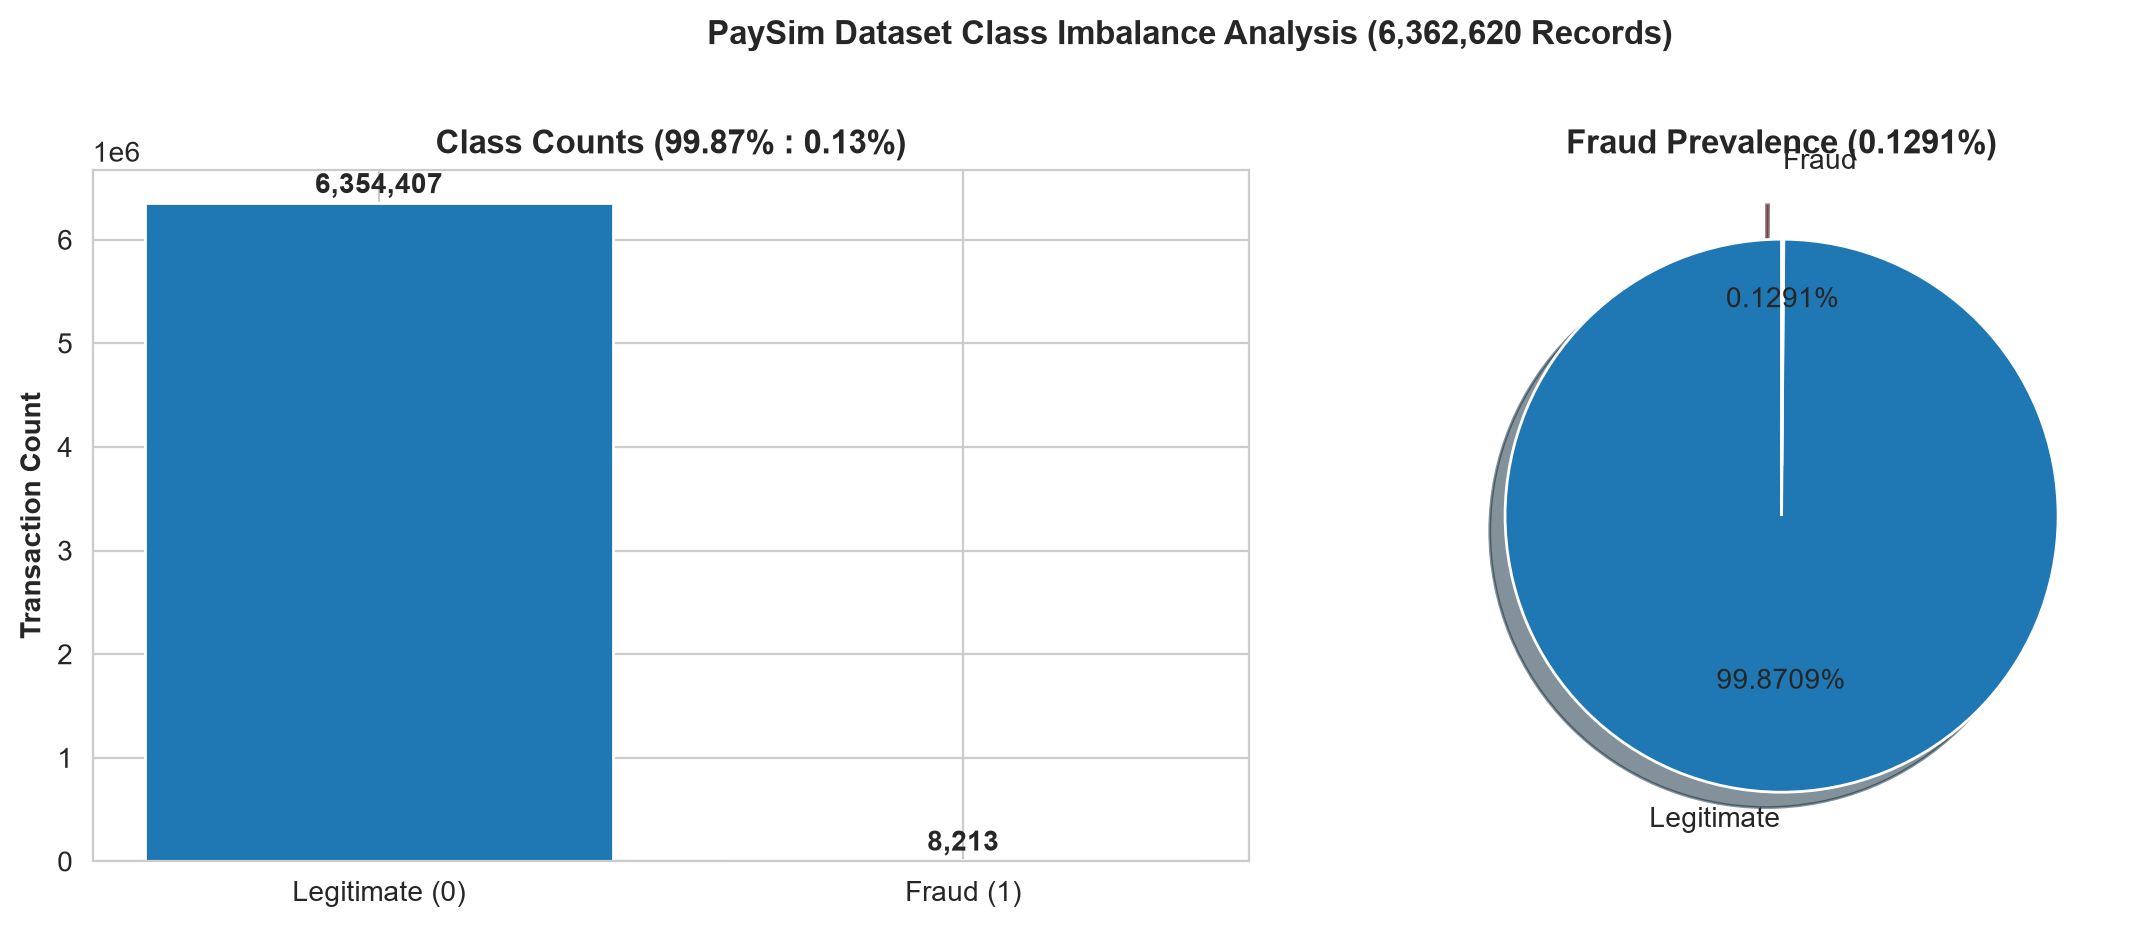

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
bars = ax1.bar(
    ["Legitimate (0)", "Fraud (1)"],
    [legit_count, fraud_count],
    color=["#1f77b4", "#d62728"],
    edgecolor="white",
)
ax1.set_ylabel("Transaction Count", fontweight="bold")
ax1.set_title(
    f"Class Counts ({legit_rate_pct:.2f}% : {fraud_rate_pct:.2f}%)",
    fontweight="bold",
)
for b, val in zip(bars, [legit_count, fraud_count]):
    ax1.text(
        b.get_x() + b.get_width() / 2,
        b.get_height() + total_rows * 0.015,
        f"{val:,}",
        ha="center",
        fontweight="bold",
    )
ax2.pie(
    [legit_count, fraud_count],
    labels=["Legitimate", "Fraud"],
    autopct="%1.4f%%",
    colors=["#1f77b4", "#d62728"],
    explode=[0, 0.18],
    shadow=True,
    startangle=90,
)
ax2.set_title(
    f"Fraud Prevalence ({fraud_rate_pct:.4f}%)",
    fontweight="bold",
)
fig.suptitle(
    f"PaySim Dataset Class Imbalance Analysis ({total_rows:,} Records)",
    fontweight="bold",
    y=1.02,
)
fig.tight_layout()
chart_path = os.path.join(FIGURES_DIR, "class_distribution.png")
fig.savefig(chart_path, dpi=200, bbox_inches="tight")
from IPython.display import Image as IPythonImage
display(IPythonImage(filename=chart_path))
plt.close(fig)

**Cell 2b.5 — Prepare Spark SQL analytics**

In [21]:
df_bronze.createOrReplaceTempView("transactions")
SQL_DIR = os.path.join(OUTPUTS_DIR, "sql_analytics")
os.makedirs(SQL_DIR, exist_ok=True)

**Cell 2b.6 — Query 1: Fraud by transaction type**

In [22]:
print("\n[QUERY 1] Fraud Distribution by Transaction Type:")

q1_df = spark.sql("""
    SELECT type,
           COUNT(*) AS total_txns,
           SUM(isFraud) AS fraud_txns,
           ROUND(AVG(isFraud) * 100, 4) AS fraud_rate_pct,
           ROUND(AVG(CASE WHEN isFraud = 1 THEN amount END), 2)
               AS avg_fraud_amount
    FROM transactions
    GROUP BY type
    ORDER BY fraud_txns DESC
""").toPandas()
display(q1_df)
q1_df.to_json(
    os.path.join(SQL_DIR, "q1_fraud_by_type.json"),
    orient="records",
    indent=2,
)


[QUERY 1] Fraud Distribution by Transaction Type:


,type,total_txns,fraud_txns,fraud_rate_pct,avg_fraud_amount
0,CASH_OUT,2237500,4116,0.1840,1455102.5900
1,TRANSFER,532909,4097,0.7688,1480891.6700
2,PAYMENT,2151495,0,0.0000,NaN
3,DEBIT,41432,0,0.0000,NaN
4,CASH_IN,1399284,0,0.0000,NaN


**Cell 2b.7 — Query 2: Hourly fraud patterns**

In [23]:
print("\n[QUERY 2] Diurnal Hourly Fraud Pattern (step % 24):")

q2_df = spark.sql("""
    SELECT (step % 24) AS hour_of_day,
           COUNT(*) AS total_txns,
           SUM(isFraud) AS fraud_txns,
           ROUND(AVG(isFraud) * 100, 4) AS fraud_rate_pct
    FROM transactions
    GROUP BY (step % 24)
    ORDER BY hour_of_day
""").toPandas()
display(q2_df.head(8))
q2_df.to_json(
    os.path.join(SQL_DIR, "q2_hourly_diurnal_patterns.json"),
    orient="records",
    indent=2,
)


[QUERY 2] Diurnal Hourly Fraud Pattern (step % 24):


,hour_of_day,total_txns,fraud_txns,fraud_rate_pct
0,0,71587,300,0.4191
1,1,27111,358,1.3205
2,2,9018,372,4.1251
3,3,2007,326,16.2431
4,4,1241,274,22.0790
5,5,1641,366,22.3035
6,6,3420,358,10.4678
7,7,8988,328,3.6493


**Cell 2b.8 — Query 3: Fraud by transaction amount**

In [24]:
print("\n[QUERY 3] Fraud by Transaction Amount Tier:")

q3_df = spark.sql("""
    SELECT CASE
               WHEN amount < 1000 THEN '1_Under_1K'
               WHEN amount < 10000 THEN '2_1K-10K'
               WHEN amount < 100000 THEN '3_10K-100K'
               WHEN amount < 1000000 THEN '4_100K-1M'
               ELSE '5_1M_and_above'
           END AS amount_tier,
           COUNT(*) AS txn_count,
           SUM(isFraud) AS fraud_count,
           ROUND(AVG(isFraud) * 100, 4) AS fraud_rate_pct
    FROM transactions
    GROUP BY 1
    ORDER BY amount_tier
""").toPandas()
display(q3_df)
q3_df.to_json(
    os.path.join(SQL_DIR, "q3_amount_bracket_analysis.json"),
    orient="records",
    indent=2,
)


[QUERY 3] Fraud by Transaction Amount Tier:


,amount_tier,txn_count,fraud_count,fraud_rate_pct
0,1_Under_1K,142642,58,0.0407
1,2_1K-10K,1143361,220,0.0192
2,3_10K-100K,2239253,1429,0.0638
3,4_100K-1M,2706738,3800,0.1404
4,5_1M_and_above,130626,2706,2.0716


**Cell 2b.9 — Query 4: Sender balance reduced to zero**

In [25]:
print("\n[QUERY 4] Account Liquidation Rate (Balance Dropped to Exactly 0):")

q4_df = spark.sql("""
    SELECT isFraud,
           SUM(
               CASE
                   WHEN oldbalanceOrg > 0 AND newbalanceOrig = 0 THEN 1
                   ELSE 0
               END
           ) AS accounts_emptied,
           ROUND(
               AVG(
                   CASE
                       WHEN oldbalanceOrg > 0 AND newbalanceOrig = 0
                           THEN 1.0
                       ELSE 0.0
                   END
               ) * 100,
               2
           ) AS emptied_pct
    FROM transactions
    GROUP BY isFraud
    ORDER BY isFraud
""").toPandas()

display(q4_df)

q4_df.to_json(
    os.path.join(SQL_DIR, "q4_sender_account_emptied.json"),
    orient="records",
    indent=2,
)


[QUERY 4] Account Liquidation Rate (Balance Dropped to Exactly 0):


,isFraud,accounts_emptied,emptied_pct
0,0,1512569,23.80
1,1,8012,97.55


**Cell 2b.10 — Query 5: Destination recipient prefixes**

In [26]:
print("\n[QUERY 5] Destination Recipient Prefix Concentration:")

q5_df = spark.sql("""
    SELECT SUBSTRING(nameDest, 1, 1) AS recipient_prefix,
           COUNT(*) AS txn_count,
           SUM(isFraud) AS fraud_txns,
           ROUND(AVG(isFraud) * 100, 4) AS fraud_rate_pct
    FROM transactions
    GROUP BY SUBSTRING(nameDest, 1, 1)
""").toPandas()

display(q5_df)

q5_df.to_json(
    os.path.join(SQL_DIR, "q5_destination_concentration.json"),
    orient="records",
    indent=2,
)


[QUERY 5] Destination Recipient Prefix Concentration:


,recipient_prefix,txn_count,fraud_txns,fraud_rate_pct
0,C,4211125,8213,0.1950
1,M,2151495,0,0.0000


**Cell 2b.11 — Filter and write the Silver dataset**

In [27]:
print("\n[SAVE] Filtering and Writing Silver Parquet ...")

df_silver = df_bronze.filter(F.col("amount") >= 0)

t_s0 = time.perf_counter()

(
    df_silver.repartition(8)
    .write.mode("overwrite")
    .parquet(SILVER_PATH)
)

sw = time.perf_counter() - t_s0

silver_rows = spark.read.parquet(SILVER_PATH).count()


[SAVE] Filtering and Writing Silver Parquet ...


**Cell 2b.12 — Save Silver metadata and display completion**

In [28]:
silver_metadata_path = os.path.join(
    OUTPUTS_DIR, "silver_metadata.json"
)

with open(silver_metadata_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "silver_rows": silver_rows,
            "write_seconds": round(sw, 2),
            "rows_removed": total_rows - silver_rows,
        },
        f,
        indent=2,
    )

print(
    f"\n  [PASS] S2-T04: Complete Data Quality Report saved -> {dq_path}"
)
print(
    f"  [PASS] S2-T05: All 5 SQL queries executed & persisted to {SQL_DIR}"
)
print(
    f"  [PASS] S2-T06: Silver Parquet written "
    f"({silver_rows:,} rows in {sw:.2f}s)"
)


  [PASS] S2-T04: Complete Data Quality Report saved -> outputs\data_quality_report.json
  [PASS] S2-T05: All 5 SQL queries executed & persisted to outputs\sql_analytics
  [PASS] S2-T06: Silver Parquet written (6,362,620 rows in 12.25s)


### **Stage 3 — Gold Layer: Feature Engineering & Chronological Split**


**Cell 3.1 — Generate transaction features**

In [29]:
from pyspark.ml.feature import StringIndexer, VectorAssembler
from IPython.display import Image as IPythonImage

df_feat = (
    df_silver
    .withColumn("txn_hour", (F.col("step") % 24).cast("integer"))
    .withColumn("txn_day", (F.col("step") / 24).cast("integer"))
    .withColumn("log_amount", F.log1p(F.col("amount")))
    .withColumn("origin_balance_before", F.col("oldbalanceOrg"))
    .withColumn("destination_balance_before", F.col("oldbalanceDest"))
    .withColumn(
        "amount_to_origin_ratio",
        F.col("amount") / (F.col("oldbalanceOrg") + 1.0),
    )
    .withColumn(
        "insufficient_origin_balance",
        F.when(
            F.col("amount") > F.col("oldbalanceOrg"), 1.0
        ).otherwise(0.0),
    )
    .withColumn(
        "dest_zero_balance_flag",
        F.when(F.col("oldbalanceDest") == 0.0, 1.0).otherwise(0.0),
    )
    .withColumn(
        "is_transfer",
        F.when(F.col("type") == "TRANSFER", 1.0).otherwise(0.0),
    )
    .withColumn(
        "is_cash_out",
        F.when(F.col("type") == "CASH_OUT", 1.0).otherwise(0.0),
    )
)

**Cell 3.2 — Define the feature dictionary**

In [30]:
feature_definitions = [
    {
        "name": "txn_hour",
        "feature_set": "F0, F1",
        "formula": "step % 24",
        "leakage_rule": "Known at transaction time (hour index 0-23)",
    },
    {
        "name": "txn_day",
        "feature_set": "F0, F1",
        "formula": "floor(step / 24)",
        "leakage_rule": "Known at transaction time (day index 0-30)",
    },
    {
        "name": "log_amount",
        "feature_set": "F0, F1",
        "formula": "log(1 + amount)",
        "leakage_rule": "Known at transaction time",
    },
    {
        "name": "origin_balance_before",
        "feature_set": "F0, F1",
        "formula": "oldbalanceOrg",
        "leakage_rule": (
            "Pre-transaction balance only; excludes newbalanceOrig"
        ),
    },
    {
        "name": "destination_balance_before",
        "feature_set": "F0, F1",
        "formula": "oldbalanceDest",
        "leakage_rule": (
            "Pre-transaction balance only; excludes newbalanceDest"
        ),
    },
    {
        "name": "type_index",
        "feature_set": "F0, F1",
        "formula": "StringIndexer(type) fit on train only",
        "leakage_rule": "Fitted strictly on training split",
    },
    {
        "name": "amount_to_origin_ratio",
        "feature_set": "F1",
        "formula": "amount / (oldbalanceOrg + 1.0)",
        "leakage_rule": (
            "Engineered ratio using only pre-transaction values"
        ),
    },
    {
        "name": "insufficient_origin_balance",
        "feature_set": "F1",
        "formula": "1.0 if amount > oldbalanceOrg else 0.0",
        "leakage_rule": (
            "Uses transaction amount and pre-transaction origin balance"
        ),
    },
    {
        "name": "dest_zero_balance_flag",
        "feature_set": "F1",
        "formula": "1.0 if oldbalanceDest == 0 else 0.0",
        "leakage_rule": (
            "Uses only the recorded pre-transaction destination balance"
        ),
    },
    {
        "name": "is_transfer",
        "feature_set": "F1",
        "formula": "1.0 if type == 'TRANSFER' else 0.0",
        "leakage_rule": "Transaction type is known at transaction time",
    },
    {
        "name": "is_cash_out",
        "feature_set": "F1",
        "formula": "1.0 if type == 'CASH_OUT' else 0.0",
        "leakage_rule": "Transaction type is known at transaction time",
    },
]

**Cell 3.3 — Save and display the feature dictionary**

In [31]:
feature_dictionary_path = os.path.join(
    OUTPUTS_DIR, "feature_dictionary.json"
)

with open(feature_dictionary_path, "w", encoding="utf-8") as f:
    json.dump(feature_definitions, f, indent=2)

print(
    f"[DICT] Generated & saved feature dictionary -> "
    f"{feature_dictionary_path}"
)

display(
    pd.DataFrame(feature_definitions)[
        ["name", "feature_set", "formula", "leakage_rule"]
    ]
)

[DICT] Generated & saved feature dictionary -> outputs\feature_dictionary.json


,name,feature_set,formula,leakage_rule
0,txn_hour,"F0, F1",step % 24,Known at transaction time (hour index 0-23)
1,txn_day,"F0, F1",floor(step / 24),Known at transaction time (day index 0-30)
2,log_amount,"F0, F1",log(1 + amount),Known at transaction time
3,origin_balance_before,"F0, F1",oldbalanceOrg,Pre-transaction balance only; excludes newbala...
4,destination_balance_before,"F0, F1",oldbalanceDest,Pre-transaction balance only; excludes newbala...
5,type_index,"F0, F1",StringIndexer(type) fit on train only,Fitted strictly on training split
6,amount_to_origin_ratio,F1,amount / (oldbalanceOrg + 1.0),Engineered ratio using only pre-transaction va...
7,insufficient_origin_balance,F1,1.0 if amount > oldbalanceOrg else 0.0,Uses transaction amount and pre-transaction or...
8,dest_zero_balance_flag,F1,1.0 if oldbalanceDest == 0 else 0.0,Uses only the recorded pre-transaction destina...
9,is_transfer,F1,1.0 if type == 'TRANSFER' else 0.0,Transaction type is known at transaction time


**Cell 3.4 — Calculate chronological split boundaries**

In [32]:
min_s, max_s = df_feat.select(
    F.min("step"), F.max("step")
).collect()[0]

total_s = max_s - min_s + 1

tr_ratio = CFG["split"]["train_ratio"]
val_ratio = CFG["split"]["val_ratio"]
test_ratio = 1 - tr_ratio - val_ratio

train_max = int(min_s + total_s * tr_ratio) - 1
val_max = int(min_s + total_s * (tr_ratio + val_ratio)) - 1

df_split = df_feat.withColumn(
    "split",
    F.when(F.col("step") <= train_max, "train")
    .when(
        (F.col("step") > train_max) & (F.col("step") <= val_max),
        "val",
    )
    .otherwise("test"),
)

**Cell 3.5 — Fit the transaction type indexer on training data**

In [33]:
idx_model = (
    StringIndexer(
        inputCol="type",
        outputCol="type_index",
        handleInvalid="keep",
    )
    .fit(df_split.filter(F.col("split") == "train"))
)

df_gold = idx_model.transform(df_split)

**Cell 3.6 — Save the Gold dataset**

In [34]:
t_gw = time.perf_counter()

(
    df_gold.write
    .mode("overwrite")
    .partitionBy("split")
    .parquet(GOLD_PATH)
)

gw_sec = time.perf_counter() - t_gw

**Cell 3.7 — Calculate split statistics**

In [35]:
split_agg = (
    spark.read.parquet(GOLD_PATH)
    .groupBy("split")
    .agg(
        F.count("*").alias("total_transactions"),
        F.sum("isFraud").alias("fraud_cases"),
        F.min("step").alias("step_min"),
        F.max("step").alias("step_max"),
    )
    .orderBy(
        F.when(F.col("split") == "train", 1)
        .when(F.col("split") == "val", 2)
        .otherwise(3)
    )
    .collect()
)

split_report = {}
split_display_rows = []

for r in split_agg:
    s = r["split"]
    n = r["total_transactions"]
    fraud_n = r["fraud_cases"]
    pct = round(fraud_n / n * 100, 4)

    split_report[s] = {
        "total_transactions": n,
        "fraud_cases": fraud_n,
        "fraud_rate_pct": pct,
        "step_min": r["step_min"],
        "step_max": r["step_max"],
    }

    split_display_rows.append({
        "Split": s.upper(),
        "Total Transactions": f"{n:,}",
        "Fraud Cases": f"{fraud_n:,}",
        "Fraud Rate (%)": f"{pct:.4f}%",
        "Step Range": f"[{r['step_min']} -> {r['step_max']}]",
    })

**Cell 3.8 — Save and display the split report**

In [36]:
split_report_path = os.path.join(OUTPUTS_DIR, "split_report.json")

with open(split_report_path, "w", encoding="utf-8") as f:
    json.dump(split_report, f, indent=2)

print(
    f"[REPORT] Calculated & saved split report -> {split_report_path}"
)

display(pd.DataFrame(split_display_rows))

[REPORT] Calculated & saved split report -> outputs\split_report.json


,Split,Total Transactions,Fraud Cases,Fraud Rate (%),Step Range
0,TRAIN,"6,010,937","5,007",0.0833%,[1 -> 445]
1,VAL,"228,103","1,552",0.6804%,[446 -> 594]
2,TEST,"123,580","1,654",1.3384%,[595 -> 743]


**Cell 3.9 — Create and save split distribution charts**

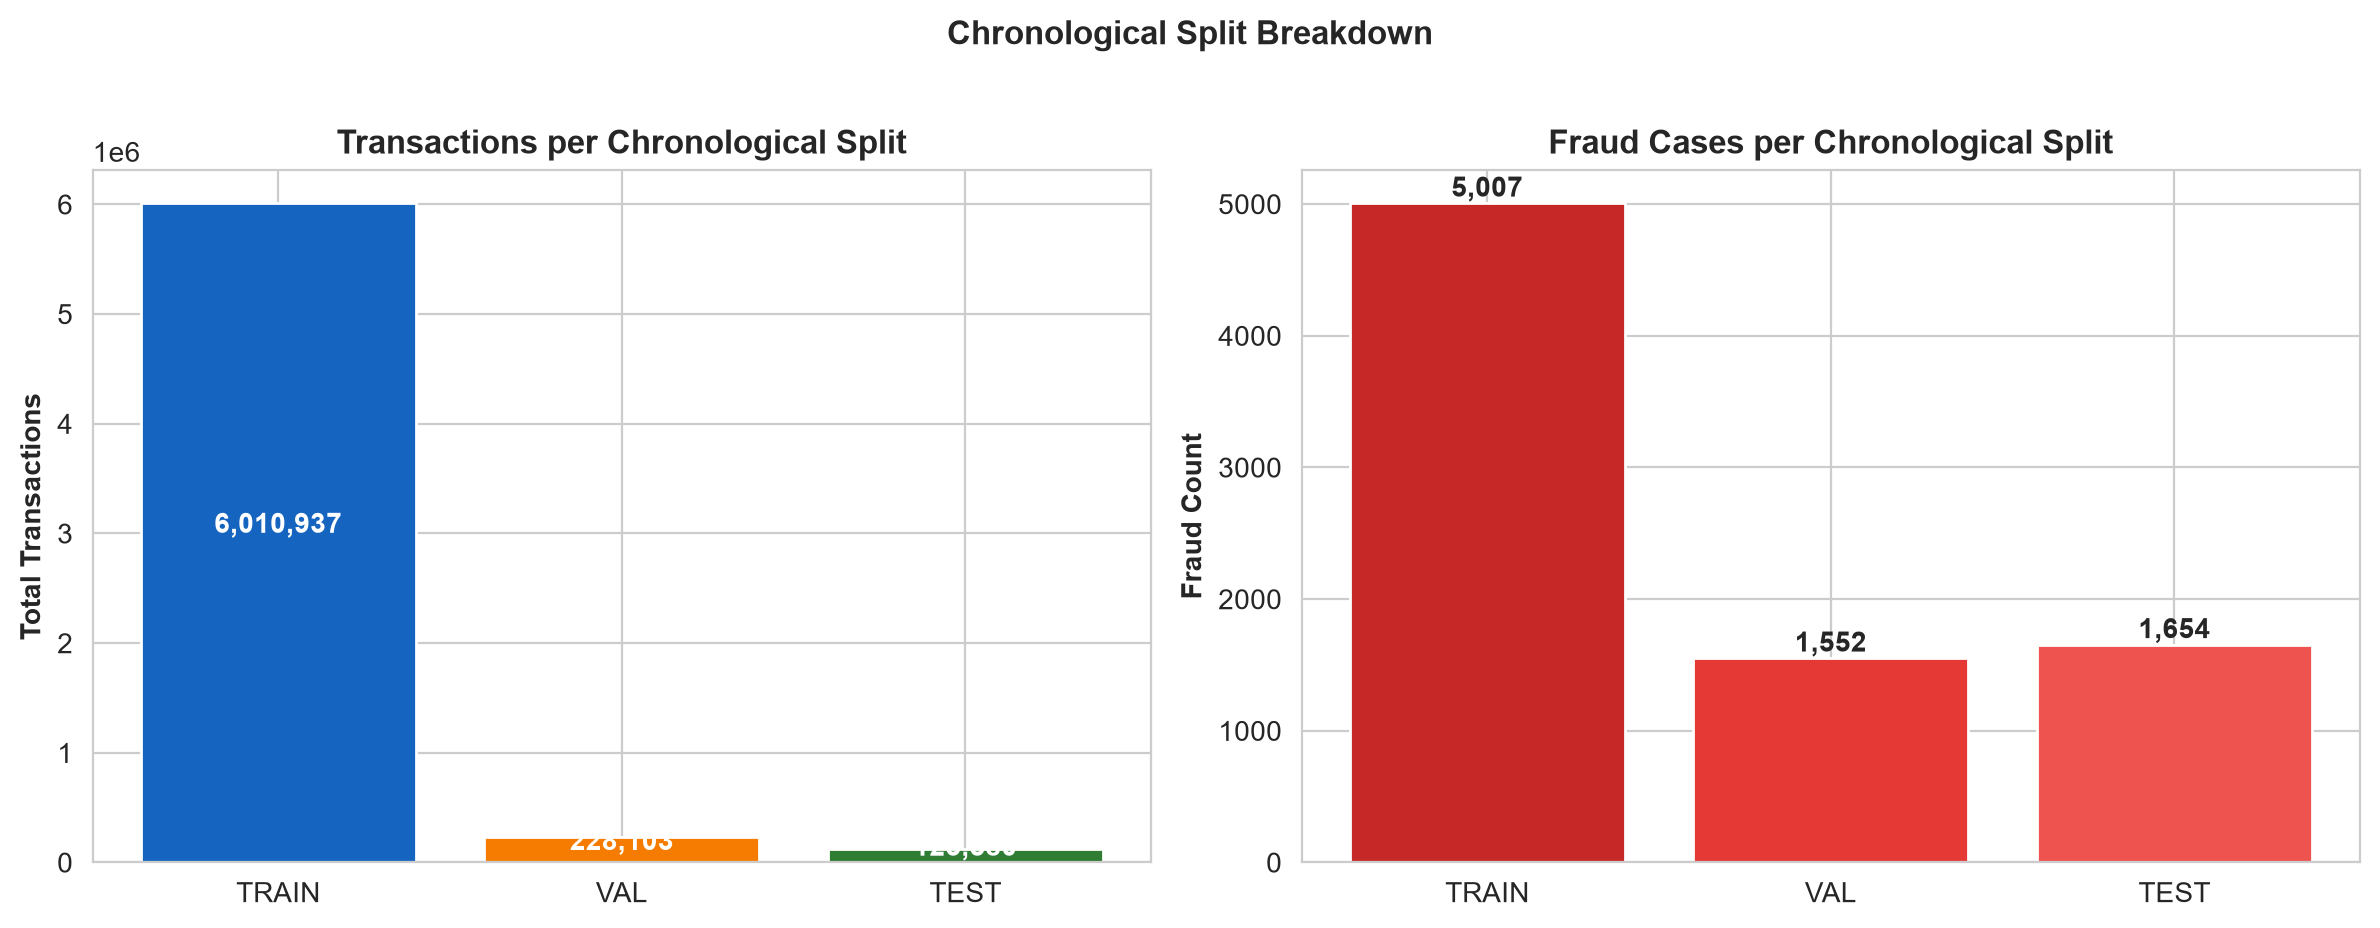

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

splits = ["TRAIN", "VAL", "TEST"]

counts = [
    split_report[s.lower()]["total_transactions"]
    for s in splits
]
frauds = [
    split_report[s.lower()]["fraud_cases"]
    for s in splits
]

bars1 = ax1.bar(
    splits,
    counts,
    color=["#1565c0", "#f57c00", "#2e7d32"],
    edgecolor="white",
)

ax1.set_ylabel("Total Transactions", fontweight="bold")
ax1.set_title(
    "Transactions per Chronological Split",
    fontweight="bold",
)

for b, c in zip(bars1, counts):
    ax1.text(
        b.get_x() + b.get_width() / 2,
        b.get_height() * 0.5,
        f"{c:,}",
        ha="center",
        color="white",
        fontweight="bold",
    )

bars2 = ax2.bar(
    splits,
    frauds,
    color=["#c62828", "#e53935", "#ef5350"],
    edgecolor="white",
)

ax2.set_ylabel("Fraud Count", fontweight="bold")
ax2.set_title(
    "Fraud Cases per Chronological Split",
    fontweight="bold",
)

for b, c in zip(bars2, frauds):
    ax2.text(
        b.get_x() + b.get_width() / 2,
        b.get_height() + 50,
        f"{c:,}",
        ha="center",
        fontweight="bold",
    )

fig.suptitle(
    "Chronological Split Breakdown",
    fontweight="bold",
    y=1.02,
)

fig.tight_layout()

split_chart_path = os.path.join(
    FIGURES_DIR, "split_distribution.png"
)

fig.savefig(split_chart_path, dpi=200, bbox_inches="tight")
display(IPythonImage(filename=split_chart_path))
plt.close(fig)

**Cell 3.10 — Display stage completion**

In [38]:
print(
    f"\n  [PASS] S3-T01: {len(feature_definitions)} features generated "
    "using transaction-time inputs"
)

print(
    f"  [PASS] S3-T02: Chronological split by time range "
    f"({tr_ratio:.0%}/{val_ratio:.0%}/{test_ratio:.0%}) "
    f"partitioned and persisted ({gw_sec:.2f}s)"
)

print(
    "  [PASS] S3-T03: StringIndexer fitted strictly on train split only"
)


  [PASS] S3-T01: 11 features generated using transaction-time inputs
  [PASS] S3-T02: Chronological split by time range (60%/20%/20%) partitioned and persisted (6.68s)
  [PASS] S3-T03: StringIndexer fitted strictly on train split only


## **Stage 4a — Spark MLlib Training, Feature Ablation & Confusion Matrices**


**Cell 4a.1 — Import tools and load data splits**

In [39]:
from pyspark.ml.classification import (
    LogisticRegression, RandomForestClassifier
)
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from IPython.display import Image as IPythonImage

df_tr = spark.read.parquet(os.path.join(GOLD_PATH, "split=train"))
df_va = spark.read.parquet(os.path.join(GOLD_PATH, "split=val"))
df_te = spark.read.parquet(os.path.join(GOLD_PATH, "split=test"))

**Cell 4a.2 — Calculate training class weights**

In [40]:
cnt = {
    int(r["isFraud"]): r["count"]
    for r in df_tr.groupBy("isFraud").count().collect()
}

n_neg, n_pos = cnt.get(0, 0), cnt.get(1, 0)

if n_neg == 0 or n_pos == 0:
    raise ValueError(
        "Training data must contain both legitimate and fraud cases."
    )

tot_tr = n_neg + n_pos
pos_weight = tot_tr / (2.0 * n_pos)
neg_weight = tot_tr / (2.0 * n_neg)

print("[WEIGHT] Class Weights computed on TRAIN ONLY:")
print(f"   Negatives (0): {n_neg:,} -> Weight: {neg_weight:.4f}")
print(f"   Positives (1): {n_pos:,} -> Weight: {pos_weight:.2f}")

df_tr_w = df_tr.withColumn(
    "cw",
    F.when(F.col("isFraud") == 1, pos_weight).otherwise(neg_weight),
)

[WEIGHT] Class Weights computed on TRAIN ONLY:
   Negatives (0): 6,005,930 -> Weight: 0.5004
   Positives (1): 5,007 -> Weight: 600.25


**Cell 4a.3 — Define the model evaluation function**

In [41]:
def evaluate_spark_model(pred_df, model_name="Model"):
    pr_eval = BinaryClassificationEvaluator(
        rawPredictionCol="probability",
        labelCol="isFraud",
        metricName="areaUnderPR",
    )

    roc_eval = BinaryClassificationEvaluator(
        rawPredictionCol="probability",
        labelCol="isFraud",
        metricName="areaUnderROC",
    )

    pr_auc = pr_eval.evaluate(pred_df)
    roc_auc = roc_eval.evaluate(pred_df)

    cm_counts = {
        (int(r["isFraud"]), int(r["prediction"])): r["count"]
        for r in (
            pred_df.groupBy("isFraud", "prediction").count().collect()
        )
    }

    tn = cm_counts.get((0, 0), 0)
    fp = cm_counts.get((0, 1), 0)
    fn = cm_counts.get((1, 0), 0)
    tp = cm_counts.get((1, 1), 0)
    tot = tn + fp + fn + tp

    p = tp / (tp + fp) if tp + fp > 0 else 0.0
    r = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * p * r / (p + r) if p + r > 0 else 0.0
    fp_1k = fp / tot * 1000 if tot > 0 else 0.0

    return {
        "model": model_name,
        "pr_auc": round(float(pr_auc), 5),
        "roc_auc": round(float(roc_auc), 5),
        "precision": round(float(p), 5),
        "recall": round(float(r), 5),
        "f1": round(float(f1), 5),
        "true_positives": int(tp),
        "false_positives": int(fp),
        "true_negatives": int(tn),
        "false_negatives": int(fn),
        "total_evaluated": int(tot),
        "false_positives_per_1000": round(float(fp_1k), 2),
        "cm": np.array([[tn, fp], [fn, tp]]),
    }

**Cell 4a.4 — Evaluate the rule baseline**

In [42]:
actual_spark_metrics = {}
cm_matrices = {}

print("\n[1/4] Evaluating Rule Baseline (isFlaggedFraud) ...")

rule_cm = {
    (int(r["isFraud"]), int(r["isFlaggedFraud"])): r["count"]
    for r in (
        df_te.groupBy("isFraud", "isFlaggedFraud").count().collect()
    )
}

tn0 = rule_cm.get((0, 0), 0)
fp0 = rule_cm.get((0, 1), 0)
fn0 = rule_cm.get((1, 0), 0)
tp0 = rule_cm.get((1, 1), 0)

tot0 = tn0 + fp0 + fn0 + tp0

p0 = tp0 / (tp0 + fp0) if tp0 + fp0 > 0 else 0.0
r0 = tp0 / (tp0 + fn0) if tp0 + fn0 > 0 else 0.0
f0 = 2 * p0 * r0 / (p0 + r0) if p0 + r0 > 0 else 0.0

if tp0 + fn0 == 0 or tn0 + fp0 == 0:
    raise ValueError(
        "Test data must contain both classes to calculate ROC-AUC."
    )

tpr0 = tp0 / (tp0 + fn0)
fpr0 = fp0 / (fp0 + tn0)
rule_roc_auc = (1 + tpr0 - fpr0) / 2

m_rule = {
    "model": "Rule_Baseline_isFlaggedFraud",
    "pr_auc": "N/A (Rule)",
    "roc_auc": round(rule_roc_auc, 5),
    "precision": round(p0, 5),
    "recall": round(r0, 5),
    "f1": round(f0, 5),
    "true_positives": tp0,
    "false_positives": fp0,
    "true_negatives": tn0,
    "false_negatives": fn0,
    "total_evaluated": tot0,
    "false_positives_per_1000": round(fp0 / tot0 * 1000, 2),
    "cm": np.array([[tn0, fp0], [fn0, tp0]]),
}

actual_spark_metrics["baseline_rule"] = m_rule
cm_matrices["Rule Baseline (isFlaggedFraud)"] = m_rule["cm"]

print(f"   TP={tp0:,} | FP={fp0:,} | FN={fn0:,} | TN={tn0:,}")
print(f"   Precision={p0:.4f} | Recall={r0:.4f} | F1={f0:.4f}")


[1/4] Evaluating Rule Baseline (isFlaggedFraud) ...
   TP=8 | FP=0 | FN=1,646 | TN=121,926
   Precision=1.0000 | Recall=0.0048 | F1=0.0096


**Cell 4a.5 — Train Logistic Regression with F0**

In [43]:
print(
    "\n[2/4] Training Spark Logistic Regression "
    "on F0 (Baseline Features) ..."
)

asm0 = VectorAssembler(inputCols=F0_COLS, outputCol="features")

tr0 = asm0.transform(df_tr_w)
te0 = asm0.transform(df_te)

lr0 = LogisticRegression(
    featuresCol="features",
    labelCol="isFraud",
    weightCol="cw",
    maxIter=CFG["models"]["logistic_regression"]["max_iter"],
    regParam=CFG["models"]["logistic_regression"]["reg_param"],
)

mod0 = lr0.fit(tr0)


[2/4] Training Spark Logistic Regression on F0 (Baseline Features) ...


**Cell 4a.6 — Evaluate Logistic Regression with F0**

In [44]:
pred0 = mod0.transform(te0)
m_lr0 = evaluate_spark_model(pred0, "Spark_LR_F0_Baseline")

actual_spark_metrics["spark_lr_f0"] = m_lr0
cm_matrices["Spark LR on F0 (Baseline Features)"] = m_lr0["cm"]

print(
    f"   PR-AUC={m_lr0['pr_auc']} | Prec={m_lr0['precision']} | "
    f"Rec={m_lr0['recall']} | F1={m_lr0['f1']}"
)

   PR-AUC=0.21858 | Prec=0.05882 | Rec=0.70979 | F1=0.10863


**Cell 4a.7 — Train and save Logistic Regression with F1**

In [45]:
print(
    "\n[3/4] Training Spark Logistic Regression "
    "on F1 (Engineered Features) ..."
)

asm1 = VectorAssembler(inputCols=F1_COLS, outputCol="features")

tr1 = asm1.transform(df_tr_w)
te1 = asm1.transform(df_te)

lr1 = LogisticRegression(
    featuresCol="features",
    labelCol="isFraud",
    weightCol="cw",
    maxIter=CFG["models"]["logistic_regression"]["max_iter"],
    regParam=CFG["models"]["logistic_regression"]["reg_param"],
)

mod1 = lr1.fit(tr1)

mod1.write().overwrite().save(
    os.path.join(MODELS_DIR, "spark_lr_f1")
)


[3/4] Training Spark Logistic Regression on F1 (Engineered Features) ...


**Cell 4a.8 — Evaluate Logistic Regression with F1**

In [46]:
pred1 = mod1.transform(te1)
m_lr1 = evaluate_spark_model(pred1, "Spark_LR_F1_Engineered")

actual_spark_metrics["spark_lr_f1"] = m_lr1
cm_matrices["Spark LR on F1 (Engineered)"] = m_lr1["cm"]

print(
    f"   PR-AUC={m_lr1['pr_auc']} | Prec={m_lr1['precision']} | "
    f"Rec={m_lr1['recall']} | F1={m_lr1['f1']}"
)

   PR-AUC=0.82494 | Prec=0.23784 | Rec=0.9873 | F1=0.38333


**Cell 4a.9 — Train and save Random Forest with F1**

In [47]:
print("\n[4/4] Training Spark Random Forest on F1 ...")

rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="isFraud",
    numTrees=CFG["models"]["random_forest"]["num_trees"],
    maxDepth=CFG["models"]["random_forest"]["max_depth"],
    seed=SEED,
)

mod_rf = rf.fit(tr1)

mod_rf.write().overwrite().save(
    os.path.join(MODELS_DIR, "spark_rf_f1")
)


[4/4] Training Spark Random Forest on F1 ...


**Cell 4a.10 — Evaluate Random Forest**

In [48]:
pred_rf = mod_rf.transform(te1)
m_rf = evaluate_spark_model(pred_rf, "Spark_RandomForest_F1")

actual_spark_metrics["spark_rf_f1"] = m_rf
cm_matrices["Spark Random Forest on F1"] = m_rf["cm"]

print(
    f"   PR-AUC={m_rf['pr_auc']} | Prec={m_rf['precision']} | "
    f"Rec={m_rf['recall']} | F1={m_rf['f1']}"
)

   PR-AUC=0.96997 | Prec=0.97343 | Rec=0.79746 | F1=0.8767


**Cell 4a.11 — Export sample predictions and metrics**

In [49]:
(
    pred1.select(
        "step", "type", "amount", "nameOrig", "nameDest",
        "isFraud", "prediction", "probability",
    )
    .limit(1000)
    .toPandas()
    .to_csv(
        os.path.join(OUTPUTS_DIR, "predictions_sample.csv"),
        index=False,
    )
)

clean_stage4_metrics = {
    k: {
        k2: v2.tolist() if isinstance(v2, np.ndarray) else v2
        for k2, v2 in v.items()
    }
    for k, v in actual_spark_metrics.items()
}

metrics_path = os.path.join(OUTPUTS_DIR, "spark_ml_metrics.json")

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(clean_stage4_metrics, f, indent=2)

print(f"\n[SAVE] Exported predictions sample & saved {metrics_path}")


[SAVE] Exported predictions sample & saved outputs\spark_ml_metrics.json


**Cell 4a.12 — Create and save confusion matrices**

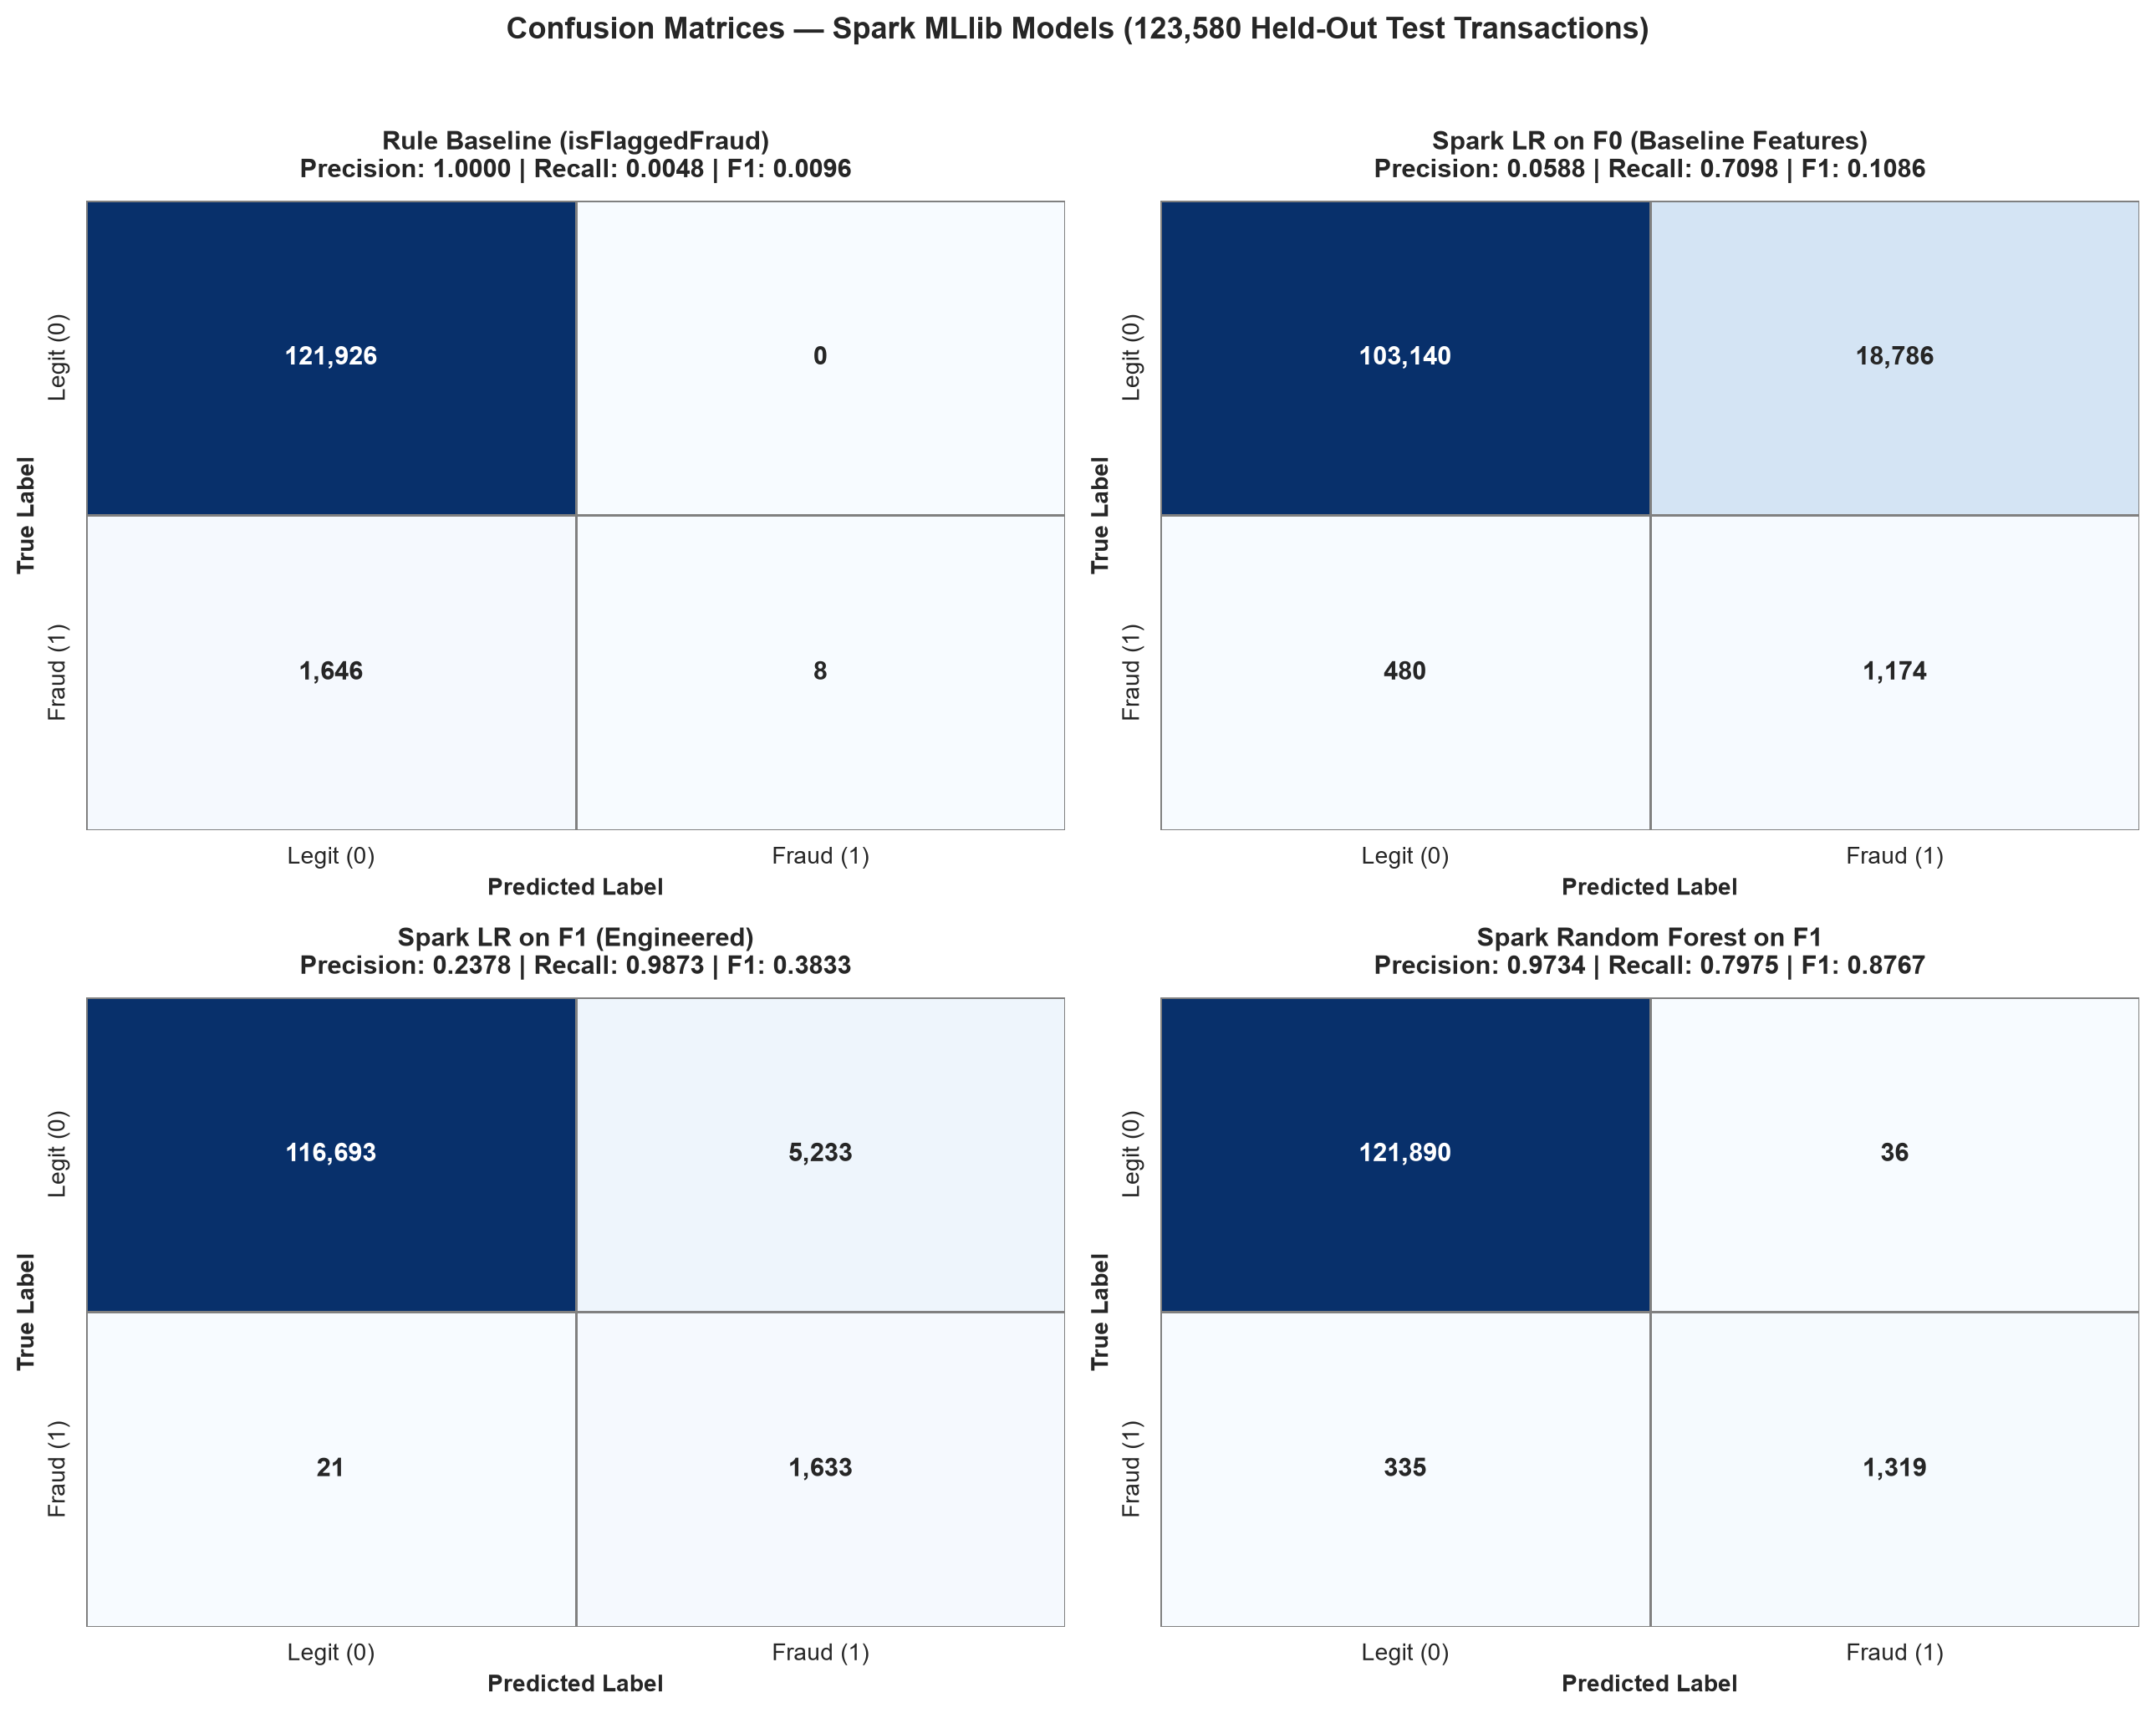

In [50]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

labels = ["Legit (0)", "Fraud (1)"]

for i, (title, cm) in enumerate(cm_matrices.items()):
    ax = axes[i]

    sns.heatmap(
        cm,
        annot=True,
        fmt=",d",
        cmap="Blues",
        cbar=False,
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
        annot_kws={"size": 11, "weight": "bold"},
        linewidths=1,
        linecolor="gray",
    )

    tn, fp, fn, tp = cm.ravel()

    prec = tp / (tp + fp) if tp + fp > 0 else 0.0
    rec = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = (
        2 * prec * rec / (prec + rec)
        if prec + rec > 0 else 0.0
    )

    ax.set_title(
        f"{title}\n"
        f"Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}",
        fontweight="bold",
        fontsize=11,
        pad=10,
    )

    ax.set_xlabel("Predicted Label", fontweight="bold")
    ax.set_ylabel("True Label", fontweight="bold")

fig.suptitle(
    f"Confusion Matrices — Spark MLlib Models "
    f"({tot0:,} Held-Out Test Transactions)",
    fontweight="bold",
    fontsize=13,
    y=1.02,
)

fig.tight_layout()

cm_chart_path = os.path.join(
    FIGURES_DIR, "confusion_matrices_spark_mllib.png"
)

fig.savefig(cm_chart_path, dpi=200, bbox_inches="tight")
display(IPythonImage(filename=cm_chart_path))
plt.close(fig)

**Cell 4a.13 — Display the model comparison table**

In [51]:
s4_table_rows = [
    {
        "Model Architecture": v["model"],
        "PR-AUC": str(v["pr_auc"]),
        "ROC-AUC": f"{v['roc_auc']:.4f}",
        "Precision": f"{v['precision']:.4f}",
        "Recall": f"{v['recall']:.4f}",
        "F1-Score": f"{v['f1']:.4f}",
        "TP": f"{v['true_positives']:,}",
        "FP": f"{v['false_positives']:,}",
        "FN": f"{v['false_negatives']:,}",
        "TN": f"{v['true_negatives']:,}",
        "FP / 1k Txns": f"{v['false_positives_per_1000']:.2f}",
    }
    for v in actual_spark_metrics.values()
]

print(
    f"\n[TABLE] Spark MLlib Performance on Test Split "
    f"({tot0:,} Transactions):"
)

display(pd.DataFrame(s4_table_rows))


[TABLE] Spark MLlib Performance on Test Split (123,580 Transactions):


,Model Architecture,PR-AUC,ROC-AUC,Precision,Recall,F1-Score,TP,FP,FN,TN,FP / 1k Txns
0,Rule_Baseline_isFlaggedFraud,N/A (Rule),0.5024,1.0000,0.0048,0.0096,8,0,"1,646","121,926",0.00
1,Spark_LR_F0_Baseline,0.21858,0.8544,0.0588,0.7098,0.1086,"1,174","18,786",480,"103,140",152.01
2,Spark_LR_F1_Engineered,0.82494,0.9935,0.2378,0.9873,0.3833,"1,633","5,233",21,"116,693",42.35
3,Spark_RandomForest_F1,0.96997,0.9995,0.9734,0.7975,0.8767,"1,319",36,335,"121,890",0.29


**Cell 4a.14 — Display stage completion and feature comparison**

In [52]:
print(
    f"\n  [PASS] S4-T01: Rule Baseline evaluated "
    f"(Recall={m_rule['recall']:.4f}, "
    f"missed frauds={m_rule['false_negatives']:,})"
)

pr_change = m_lr1["pr_auc"] - m_lr0["pr_auc"]

if m_lr0["pr_auc"] > 0:
    relative_change_pct = pr_change / m_lr0["pr_auc"] * 100
    change_text = f"{relative_change_pct:+.2f}% relative change"
else:
    change_text = (
        "relative change undefined because F0 PR-AUC is zero"
    )

print(
    f"  [PASS] S4-T02: Feature ablation evaluated "
    f"(F0 PR-AUC={m_lr0['pr_auc']:.5f} -> "
    f"F1 PR-AUC={m_lr1['pr_auc']:.5f}; {change_text})"
)

print(
    f"  [PASS] S4-T03: Random Forest evaluated "
    f"(Precision={m_rf['precision']:.2%}, "
    f"Recall={m_rf['recall']:.2%}, "
    f"FP per 1,000 transactions="
    f"{m_rf['false_positives_per_1000']:.2f})"
)

print(
    f"  [PASS] S4-T04: Confusion matrices and metrics saved "
    f"-> {metrics_path}"
)


  [PASS] S4-T01: Rule Baseline evaluated (Recall=0.0048, missed frauds=1,646)
  [PASS] S4-T02: Feature ablation evaluated (F0 PR-AUC=0.21858 -> F1 PR-AUC=0.82494; +277.41% relative change)
  [PASS] S4-T03: Random Forest evaluated (Precision=97.34%, Recall=79.75%, FP per 1,000 transactions=0.29)
  [PASS] S4-T04: Confusion matrices and metrics saved -> outputs\spark_ml_metrics.json


## **Stage 4b — Dedicated Experiment: Impact of Class Imbalance Handling Techniques**


**Cell 4b.1 — Import tools**

In [53]:
from imblearn.over_sampling import SMOTENC
from sklearn.linear_model import LogisticRegression as SK_LR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    auc,
    confusion_matrix,
)
from IPython.display import Image as IPythonImage

**Cell 4b.2 — Prepare training and test samples**

In [54]:
tr_sample = (
    df_tr.sample(withReplacement=False, fraction=0.02, seed=SEED)
    .limit(100000)
    .toPandas()
)

X_tr_sub = tr_sample[F1_COLS].to_numpy(dtype=float)
y_tr_sub = tr_sample["isFraud"].to_numpy(dtype=int)

te_sample = (
    df_te.sample(withReplacement=False, fraction=0.10, seed=SEED)
    .limit(10000)
    .toPandas()
)

X_te_eval = te_sample[F1_COLS].to_numpy(dtype=float)
y_te_eval = te_sample["isFraud"].to_numpy(dtype=int)

print(
    f"Training context: {len(y_tr_sub):,} transactions "
    f"({int(y_tr_sub.sum()):,} natural frauds)"
)
print(
    f"Test evaluation : {len(y_te_eval):,} transactions "
    f"({int(y_te_eval.sum()):,} natural frauds)"
)

if set(np.unique(y_tr_sub)) != {0, 1}:
    raise ValueError("Training sample must contain both classes.")

if set(np.unique(y_te_eval)) != {0, 1}:
    raise ValueError("Test sample must contain both classes.")

Training context: 100,000 transactions (96 natural frauds)
Test evaluation : 10,000 transactions (134 natural frauds)


**Cell 4b.3 — Identify categorical features and scale numerical features**

In [55]:
categorical_names = [
    "type_index",
    "insufficient_origin_balance",
    "dest_zero_balance_flag",
    "is_transfer",
    "is_cash_out",
]

cat_cols = [
    F1_COLS.index(name)
    for name in categorical_names
]

num_cols = [
    i for i, name in enumerate(F1_COLS)
    if name not in categorical_names
]

scaler_imb = StandardScaler()

X_tr_scaled = X_tr_sub.copy()
X_te_scaled = X_te_eval.copy()

X_tr_scaled[:, num_cols] = scaler_imb.fit_transform(
    X_tr_sub[:, num_cols]
)

X_te_scaled[:, num_cols] = scaler_imb.transform(
    X_te_eval[:, num_cols]
)

**Cell 4b.4 — Train and predict with unweighted Logistic Regression**

In [56]:
print(
    "\n[Strategy 1] Training Unweighted "
    "Logistic Regression (Scaled) ..."
)

clf_unw = SK_LR(
    max_iter=300,
    random_state=SEED,
)

clf_unw.fit(X_tr_scaled, y_tr_sub)

prob_unw = clf_unw.predict_proba(X_te_scaled)[:, 1]
pred_unw = (prob_unw >= 0.5).astype(int)


[Strategy 1] Training Unweighted Logistic Regression (Scaled) ...


**Cell 4b.5 — Train and predict with class-weighted Logistic Regression**

In [57]:
print(
    "[Strategy 2] Training Class-Weighted "
    "Logistic Regression (Scaled) ..."
)

clf_weighted = SK_LR(
    class_weight="balanced",
    max_iter=300,
    random_state=SEED,
)

clf_weighted.fit(X_tr_scaled, y_tr_sub)

prob_wgt = clf_weighted.predict_proba(X_te_scaled)[:, 1]
pred_wgt = (prob_wgt >= 0.5).astype(int)

[Strategy 2] Training Class-Weighted Logistic Regression (Scaled) ...


**Cell 4b.6 — Apply SMOTENC to training data**

In [58]:
print(
    "[Strategy 3] Applying SMOTENC to Scaled Training Data Only "
    "(Categorical Preservation) ..."
)

minority_count = int(
    np.bincount(y_tr_sub, minlength=2).min()
)

if minority_count < 2:
    raise ValueError(
        "SMOTENC requires at least two minority-class examples."
    )

smotenc = SMOTENC(
    categorical_features=cat_cols,
    random_state=SEED,
    k_neighbors=min(5, minority_count - 1),
)

X_tr_smote, y_tr_smote = smotenc.fit_resample(
    X_tr_scaled,
    y_tr_sub,
)

print(
    f"   SMOTENC balanced training set: "
    f"{len(y_tr_smote):,} records "
    f"({int(y_tr_smote.sum()):,} frauds, "
    f"{len(y_tr_smote) - int(y_tr_smote.sum()):,} legit)"
)

[Strategy 3] Applying SMOTENC to Scaled Training Data Only (Categorical Preservation) ...
   SMOTENC balanced training set: 199,808 records (99,904 frauds, 99,904 legit)


**Cell 4b.7 — Train and predict with SMOTENC Logistic Regression**

In [59]:
clf_smote = SK_LR(
    max_iter=300,
    random_state=SEED,
)

clf_smote.fit(X_tr_smote, y_tr_smote)

prob_smote = clf_smote.predict_proba(X_te_scaled)[:, 1]
pred_smote = (prob_smote >= 0.5).astype(int)

**Cell 4b.8 — Define the evaluation function**

In [60]:
def get_imbalance_metrics(y_true, y_pred, y_prob, name):
    pc, rc, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(rc, pc)

    p = precision_score(y_true, y_pred, zero_division=0)
    r = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    return {
        "Strategy": name,
        "PR-AUC": round(float(pr_auc), 4),
        "Precision": round(float(p), 4),
        "Recall": round(float(r), 4),
        "F1-Score": round(float(f1), 4),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "cm": cm,
    }

**Cell 4b.9 — Compare the three strategies**

In [61]:
imbalance_results = [
    get_imbalance_metrics(
        y_te_eval,
        pred_unw,
        prob_unw,
        "1. Unweighted (Scaled)",
    ),
    get_imbalance_metrics(
        y_te_eval,
        pred_wgt,
        prob_wgt,
        "2. Class-Weighted (Scaled)",
    ),
    get_imbalance_metrics(
        y_te_eval,
        pred_smote,
        prob_smote,
        "3. SMOTENC (Scaled)",
    ),
]

df_imb = pd.DataFrame(imbalance_results)

print("\n[TABLE] Class Imbalance Handling Comparison Table:")

display(
    df_imb[
        [
            "Strategy", "PR-AUC", "Precision", "Recall",
            "F1-Score", "TP", "FP", "FN", "TN",
        ]
    ]
)


[TABLE] Class Imbalance Handling Comparison Table:


,Strategy,PR-AUC,Precision,Recall,F1-Score,TP,FP,FN,TN
0,1. Unweighted (Scaled),0.8449,1.0000,0.4925,0.6600,66,0,68,9866
1,2. Class-Weighted (Scaled),0.8469,0.2409,0.9925,0.3878,133,419,1,9447
2,3. SMOTENC (Scaled),0.8149,0.2495,0.9776,0.3976,131,394,3,9472


**Cell 4b.10 — Save comparison results**

In [62]:
imbalance_path = os.path.join(
    OUTPUTS_DIR, "imbalance_comparison.json"
)

clean_imb = [
    {
        k: v.tolist() if isinstance(v, np.ndarray) else v
        for k, v in result.items()
    }
    for result in imbalance_results
]

with open(imbalance_path, "w", encoding="utf-8") as f:
    json.dump(clean_imb, f, indent=2)

**Cell 4b.11 — Create and save the comparison chart**

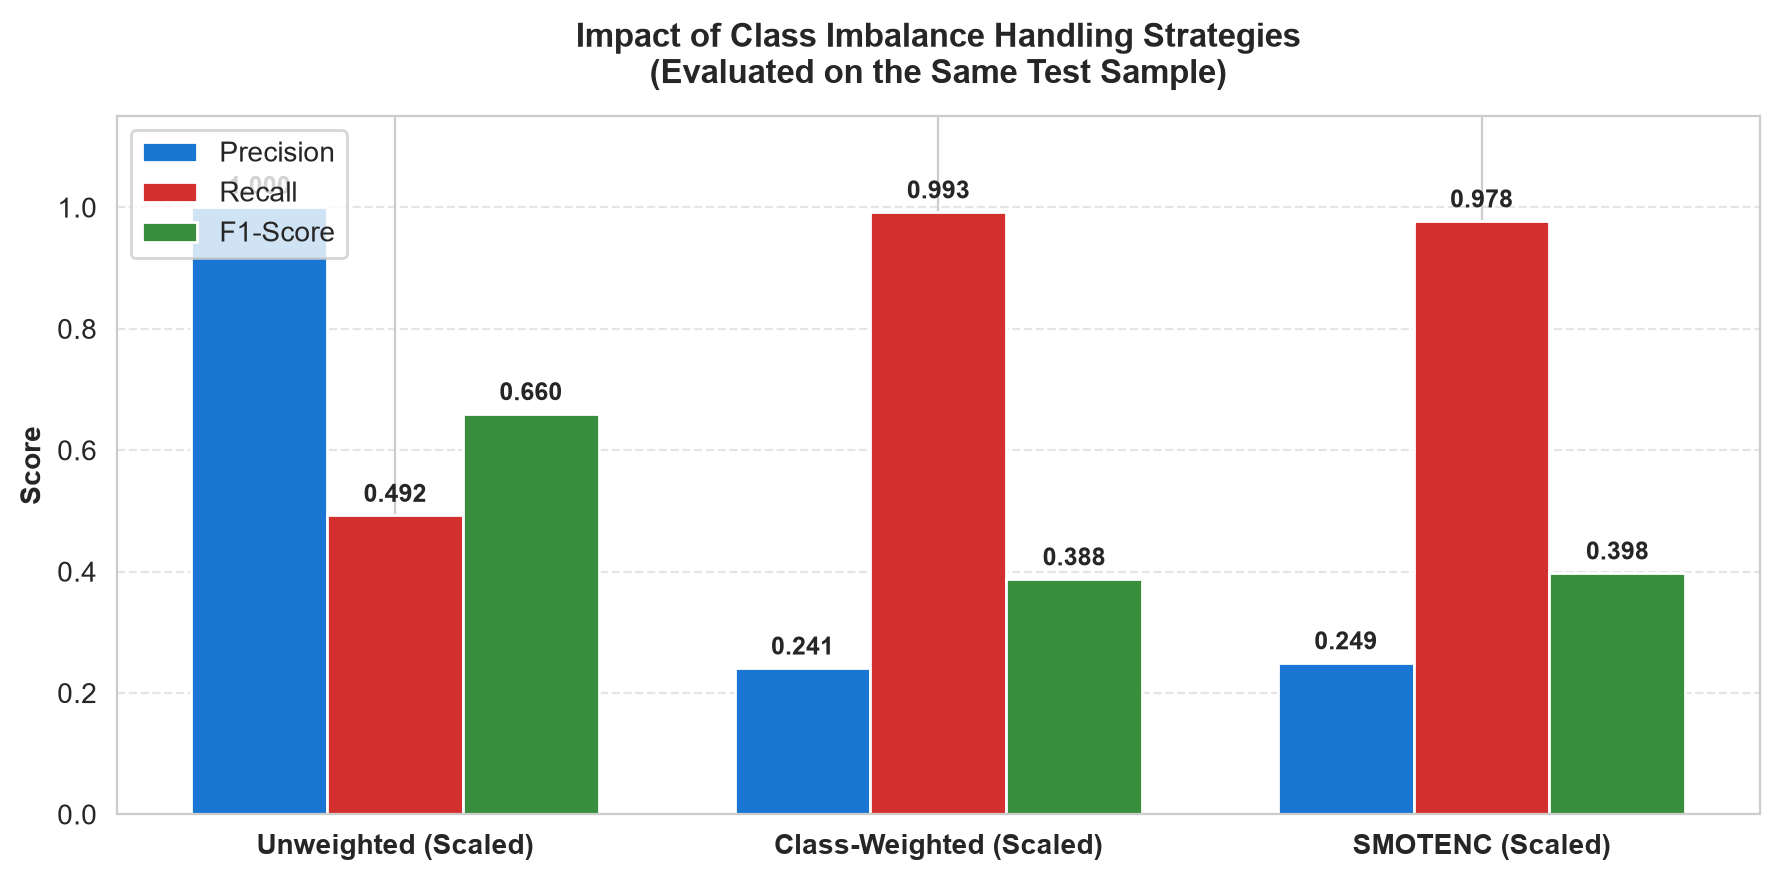

In [63]:
fig, ax = plt.subplots(figsize=(9, 4.5))

strategies = [
    result["Strategy"].split(". ", 1)[1]
    for result in imbalance_results
]

x_pos = np.arange(len(strategies))
width = 0.25

rects1 = ax.bar(
    x_pos - width,
    [result["Precision"] for result in imbalance_results],
    width,
    label="Precision",
    color="#1976d2",
)

rects2 = ax.bar(
    x_pos,
    [result["Recall"] for result in imbalance_results],
    width,
    label="Recall",
    color="#d32f2f",
)

rects3 = ax.bar(
    x_pos + width,
    [result["F1-Score"] for result in imbalance_results],
    width,
    label="F1-Score",
    color="#388e3c",
)

ax.set_ylabel("Score", fontweight="bold")
ax.set_title(
    "Impact of Class Imbalance Handling Strategies\n"
    "(Evaluated on the Same Test Sample)",
    fontweight="bold",
    pad=12,
)

ax.set_xticks(x_pos)
ax.set_xticklabels(strategies, fontweight="bold")
ax.set_ylim(0, 1.15)
ax.legend(loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.5)

for rects in [rects1, rects2, rects3]:
    for bar in rects:
        h = bar.get_height()

        if h > 0:
            ax.annotate(
                f"{h:.3f}",
                xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 3),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=9,
                fontweight="bold",
            )

fig.tight_layout()

imbalance_chart_path = os.path.join(
    FIGURES_DIR, "imbalance_handling_comparison.png"
)

fig.savefig(
    imbalance_chart_path,
    dpi=200,
    bbox_inches="tight",
)

display(IPythonImage(filename=imbalance_chart_path))
plt.close(fig)

**Cell 4b.12 — Compare false positives and display completion**

In [64]:
fp_w = imbalance_results[1]["FP"]
fp_s = imbalance_results[2]["FP"]

f1_w = imbalance_results[1]["F1-Score"]
f1_s = imbalance_results[2]["F1-Score"]

if fp_s == fp_w:
    fp_comparison = f"no change in false positives ({fp_s:,})"

elif fp_w == 0:
    fp_comparison = (
        f"false positives increased from 0 to {fp_s:,}; "
        "percentage change is undefined"
    )

elif fp_s < fp_w:
    fp_reduction_pct = (fp_w - fp_s) / fp_w * 100
    fp_comparison = (
        f"{fp_reduction_pct:.1f}% reduction in false positives"
    )

else:
    fp_increase_pct = (fp_s - fp_w) / fp_w * 100
    fp_comparison = (
        f"{fp_increase_pct:.1f}% increase in false positives"
    )

print(
    "\n  [PASS] S4b-T01: Unweighted baseline evaluated "
    "on scaled features "
    f"(Recall={imbalance_results[0]['Recall']:.4f})"
)

print(
    "  [PASS] S4b-T02: SMOTENC applied to scaled training data only "
    "and evaluated on held-out test data"
)

print(
    f"  [PASS] S4b-T03: SMOTENC F1={f1_s:.4f} "
    f"(vs {f1_w:.4f} weighted), "
    f"with {fp_comparison} vs. weighting"
)


  [PASS] S4b-T01: Unweighted baseline evaluated on scaled features (Recall=0.4925)
  [PASS] S4b-T02: SMOTENC applied to scaled training data only and evaluated on held-out test data
  [PASS] S4b-T03: SMOTENC F1=0.3976 (vs 0.3878 weighted), with 6.0% reduction in false positives vs. weighting


## **Stage 4c — Validation-Based Classification Threshold Optimization**

**Cell 4c.1 — Validation results table and best threshold**

In [65]:
from sklearn.metrics import precision_score, recall_score, f1_score
from IPython.display import Image as IPythonImage

va1 = asm1.transform(df_va)
val_preds = (
    mod1.transform(va1)
    .select("isFraud", "probability")
    .toPandas()
)

val_y = val_preds["isFraud"].to_numpy(dtype=int)
val_probs = np.array([p[1] for p in val_preds["probability"]])

thresholds = np.round(np.arange(0.10, 0.95, 0.05), 2)
best_tau = 0.5
best_val_f1 = -1.0
threshold_sweep = []

for tau in thresholds:
    tau = float(tau)
    p_tau = (val_probs >= tau).astype(int)

    f1_tau = f1_score(val_y, p_tau, zero_division=0)
    prec_tau = precision_score(val_y, p_tau, zero_division=0)
    rec_tau = recall_score(val_y, p_tau, zero_division=0)

    threshold_sweep.append({
        "Threshold (tau)": tau,
        "Precision": round(float(prec_tau), 4),
        "Recall": round(float(rec_tau), 4),
        "F1-Score": round(float(f1_tau), 4),
    })

    if f1_tau > best_val_f1:
        best_val_f1 = float(f1_tau)
        best_tau = tau

df_sweep = pd.DataFrame(threshold_sweep)

print(
    "[TUNING] Best Validation Threshold Among Tested Values: "
    f"tau* = {best_tau:.2f} "
    f"(Validation F1 = {best_val_f1:.4f})"
)

display(df_sweep.iloc[::2])

[TUNING] Best Validation Threshold Among Tested Values: tau* = 0.90 (Validation F1 = 0.6955)


,Threshold (tau),Precision,Recall,F1-Score
0,0.1000,0.0356,0.9981,0.0688
2,0.2000,0.1063,0.9968,0.1921
4,0.3000,0.1316,0.9961,0.2326
6,0.4000,0.1368,0.9942,0.2405
8,0.5000,0.1425,0.9897,0.2492
10,0.6000,0.1566,0.9794,0.2700
12,0.7000,0.1962,0.9523,0.3253
14,0.8000,0.3217,0.8860,0.4720
16,0.9000,0.7071,0.6843,0.6955


**Cell 4c.2 — Test performance comparison table**

In [66]:
test_preds = (
    mod1.transform(te1)
    .select("isFraud", "probability")
    .toPandas()
)

test_y = test_preds["isFraud"].to_numpy(dtype=int)
test_probs = np.array([p[1] for p in test_preds["probability"]])

p_def = (test_probs >= 0.50).astype(int)

f1_def = float(f1_score(test_y, p_def, zero_division=0))
prec_def = float(precision_score(test_y, p_def, zero_division=0))
rec_def = float(recall_score(test_y, p_def, zero_division=0))

p_tuned = (test_probs >= best_tau).astype(int)

f1_tuned = float(f1_score(test_y, p_tuned, zero_division=0))
prec_tuned = float(precision_score(test_y, p_tuned, zero_division=0))
rec_tuned = float(recall_score(test_y, p_tuned, zero_division=0))

test_label = f"Held-Out Test ({len(test_y):,} transactions)"

tuning_comparison = [
    {
        "Evaluation Set": test_label,
        "Decision Threshold": "Default (tau = 0.50)",
        "Precision": round(prec_def, 4),
        "Recall": round(rec_def, 4),
        "F1-Score": round(f1_def, 4),
    },
    {
        "Evaluation Set": test_label,
        "Decision Threshold": (
            f"Tuned on Validation (tau* = {best_tau:.2f})"
        ),
        "Precision": round(prec_tuned, 4),
        "Recall": round(rec_tuned, 4),
        "F1-Score": round(f1_tuned, 4),
    },
]

print(
    "\n[TABLE] Test Set Performance Before vs. "
    "After Threshold Optimization:"
)

display(pd.DataFrame(tuning_comparison))


[TABLE] Test Set Performance Before vs. After Threshold Optimization:


,Evaluation Set,Decision Threshold,Precision,Recall,F1-Score
0,"Held-Out Test (123,580 transactions)",Default (tau = 0.50),0.2378,0.9873,0.3833
1,"Held-Out Test (123,580 transactions)",Tuned on Validation (tau* = 0.90),0.8232,0.6360,0.7176


**Cell 4c.3 — Threshold optimization figure**

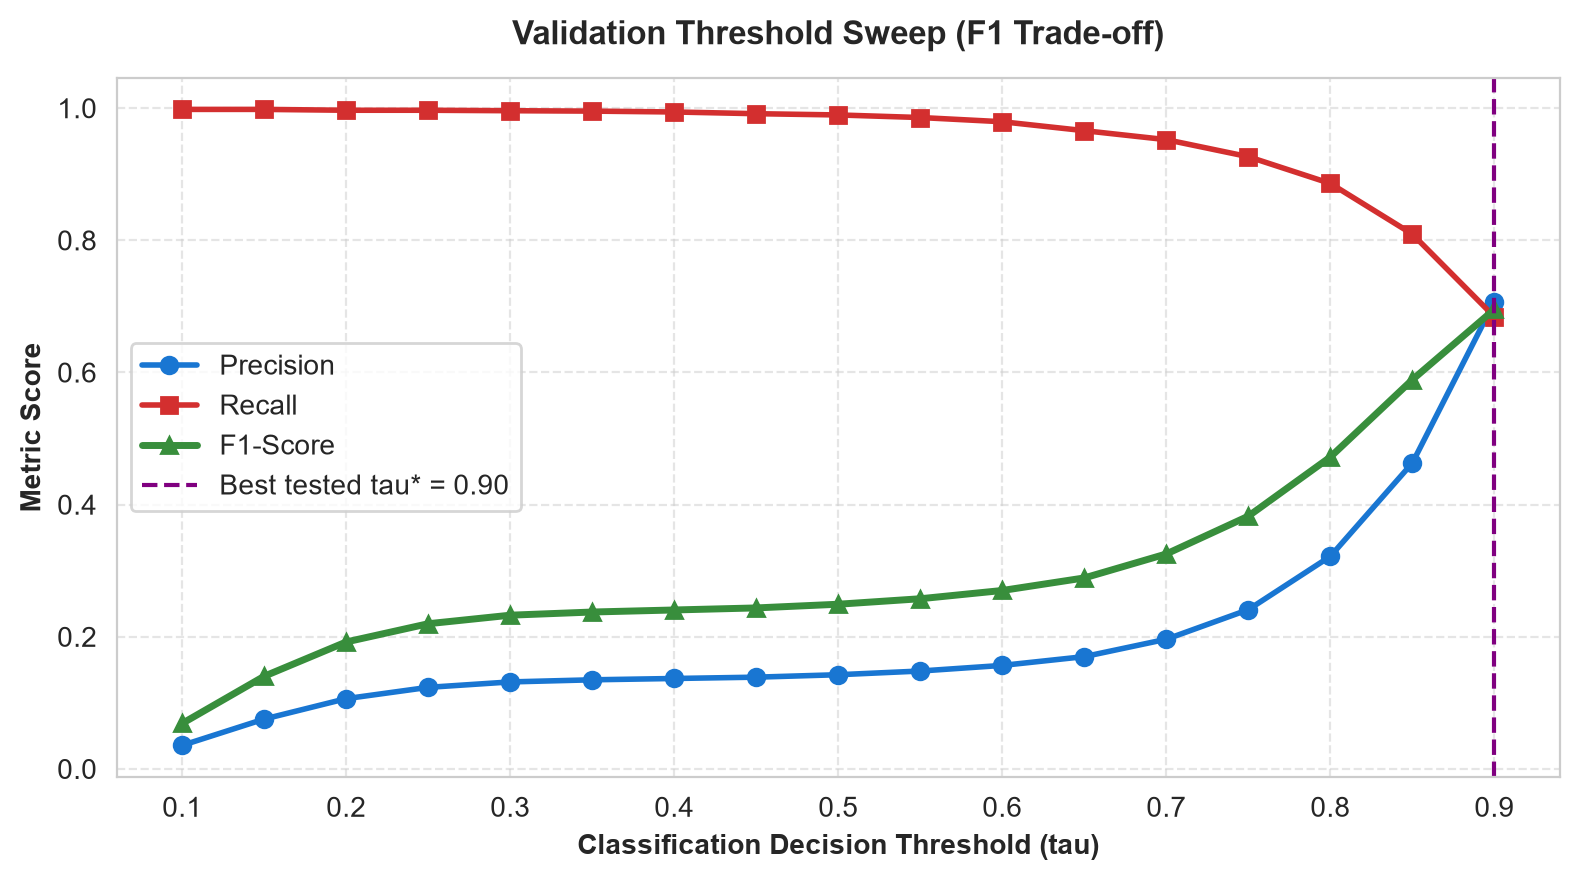

In [67]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    df_sweep["Threshold (tau)"],
    df_sweep["Precision"],
    marker="o",
    color="#1976d2",
    label="Precision",
    lw=2,
)

ax.plot(
    df_sweep["Threshold (tau)"],
    df_sweep["Recall"],
    marker="s",
    color="#d32f2f",
    label="Recall",
    lw=2,
)

ax.plot(
    df_sweep["Threshold (tau)"],
    df_sweep["F1-Score"],
    marker="^",
    color="#388e3c",
    label="F1-Score",
    lw=2.5,
)

ax.axvline(
    best_tau,
    color="purple",
    linestyle="--",
    lw=1.5,
    label=f"Best tested tau* = {best_tau:.2f}",
)

ax.set_xlabel(
    "Classification Decision Threshold (tau)",
    fontweight="bold",
)
ax.set_ylabel("Metric Score", fontweight="bold")
ax.set_title(
    "Validation Threshold Sweep (F1 Trade-off)",
    fontweight="bold",
    pad=12,
)

ax.legend(loc="center left")
ax.grid(True, linestyle="--", alpha=0.5)

fig.tight_layout()

threshold_chart_path = os.path.join(
    FIGURES_DIR, "threshold_optimization_curve.png"
)

fig.savefig(threshold_chart_path, dpi=200, bbox_inches="tight")
display(IPythonImage(filename=threshold_chart_path))
plt.close(fig)

**Cell 4c.4 — Save report and display final results**

In [68]:
threshold_report_path = os.path.join(
    OUTPUTS_DIR, "threshold_tuning.json"
)

with open(threshold_report_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "optimal_threshold": best_tau,
            "selection_scope": (
                "Best threshold among tested values on validation data"
            ),
            "validation_f1": round(best_val_f1, 4),
            "test_comparison": tuning_comparison,
            "sweep": threshold_sweep,
        },
        f,
        indent=2,
    )

print(f"\n[SAVE] Threshold report saved -> {threshold_report_path}")

print(
    "  [PASS] S4c-T01: Decision threshold selected "
    "using validation data only"
)

if f1_def > 0:
    f1_change_pct = (f1_tuned - f1_def) / f1_def * 100
    f1_gain_str = f"{f1_change_pct:+.1f}% relative change"
else:
    f1_gain_str = f"{f1_tuned - f1_def:+.4f} absolute change"

if f1_tuned > f1_def:
    f1_direction = "improved"
elif f1_tuned < f1_def:
    f1_direction = "decreased"
else:
    f1_direction = "remained unchanged"

print(
    "  [PASS] S4c-T02: At the validation-selected threshold "
    f"(tau* = {best_tau:.2f}), test F1 {f1_direction}: "
    f"{f1_def:.4f} -> {f1_tuned:.4f} ({f1_gain_str})"
)


[SAVE] Threshold report saved -> outputs\threshold_tuning.json
  [PASS] S4c-T01: Decision threshold selected using validation data only
  [PASS] S4c-T02: At the validation-selected threshold (tau* = 0.90), test F1 improved: 0.3833 -> 0.7176 (+87.2% relative change)


## **Stage 5 — Pretrained AI (TabPFN) Fair Comparison**


**Cell 5.1 — Prepare samples and display the experiment setup**

In [69]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    precision_recall_curve, auc, roc_auc_score, confusion_matrix,
)
from IPython.display import Image as IPythonImage

ctx_pd = (
    df_tr.filter(F.col("isFraud") == 1)
    .orderBy(F.rand(SEED))
    .limit(2500)
    .unionByName(
        df_tr.filter(F.col("isFraud") == 0)
        .orderBy(F.rand(SEED + 1))
        .limit(2500)
    )
    .toPandas()
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

X_tr_5k = ctx_pd[F1_COLS].to_numpy(dtype=float)
y_tr_5k = ctx_pd["isFraud"].to_numpy(dtype=int)

if set(np.unique(y_tr_5k)) != {0, 1}:
    raise ValueError("Training context must contain both classes.")

te_pd_5k = (
    df_te.orderBy(F.rand(SEED))
    .limit(5000)
    .toPandas()
    .reset_index(drop=True)
)

te_pd_5k["txn_id"] = np.arange(len(te_pd_5k), dtype=np.int64)

X_te_5k = te_pd_5k[F1_COLS].to_numpy(dtype=float)
y_te_5k = te_pd_5k["isFraud"].to_numpy(dtype=int)

context_size = len(y_tr_5k)
test_size = len(y_te_5k)
nat_fraud_count = int(y_te_5k.sum())

if set(np.unique(y_te_5k)) != {0, 1}:
    raise ValueError(
        "Test sample must contain both classes for ROC-AUC."
    )

test_prevalence_pct = nat_fraud_count / test_size * 100

print(
    f"[CONTEXT] {context_size:,} training transactions | "
    f"Fraud: {int(y_tr_5k.sum()):,} | "
    f"Legitimate: {int((y_tr_5k == 0).sum()):,}"
)
print(
    f"[TEST] Identical test sample for all models: "
    f"{test_size:,} transactions | "
    f"Fraud: {nat_fraud_count:,} ({test_prevalence_pct:.2f}%)"
)
print(
    f"[PROTOCOL] TabPFN/fallback uses {context_size:,} "
    f"balanced training records; "
    f"Spark models use {tot_tr:,} original training records."
)

[CONTEXT] 5,000 training transactions | Fraud: 2,500 | Legitimate: 2,500
[TEST] Identical test sample for all models: 5,000 transactions | Fraud: 66 (1.32%)
[PROTOCOL] TabPFN/fallback uses 5,000 balanced training records; Spark models use 6,010,937 original training records.


**Cell 5.2 — Evaluate all models and display the comparison table**

In [70]:
def eval_numpy_preds(y_true, y_pred, y_prob, name):
    pc, rc, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(rc, pc)
    roc_auc = roc_auc_score(y_true, y_prob)

    p = precision_score(y_true, y_pred, zero_division=0)
    r = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    return {
        "model": name,
        "pr_auc": round(float(pr_auc), 5),
        "roc_auc": round(float(roc_auc), 5),
        "precision": round(float(p), 5),
        "recall": round(float(r), 5),
        "f1": round(float(f1), 5),
        "true_positives": int(tp),
        "false_positives": int(fp),
        "true_negatives": int(tn),
        "false_negatives": int(fn),
        "total_evaluated": int(len(y_true)),
        "cm": cm,
    }


actual_stage5_metrics = {}
cm_5k_dict = {}
tabpfn_error = None

try:
    from tabpfn import TabPFNClassifier

    t0_tab = time.perf_counter()

    tab_clf = TabPFNClassifier(device="cpu", random_state=SEED)
    tab_clf.fit(X_tr_5k, y_tr_5k)

    tab_prob = tab_clf.predict_proba(X_te_5k)[:, 1]
    tab_fit_predict_seconds = time.perf_counter() - t0_tab

except Exception as e:
    tabpfn_error = f"{type(e).__name__}: {e}"

    print(f"\n[WARN] TabPFN execution failed: {tabpfn_error}")
    print(
        "[FALLBACK] Training a Scikit-Learn Random Forest "
        "on the same context. This is not pretrained AI."
    )

if tabpfn_error is None:
    tab_pred = (tab_prob >= 0.5).astype(int)

    m_tab = eval_numpy_preds(
        y_te_5k, tab_pred, tab_prob, "TabPFN_Pretrained"
    )

    m_tab["status"] = "SUCCESS_TABPFN_INFERENCE"
    m_tab["fit_predict_seconds"] = round(tab_fit_predict_seconds, 2)
    m_tab["training_context_size"] = context_size

    tab_model_label = "TabPFN Pretrained"

    print("\n[PASS] Genuine TabPFN inference executed successfully.")

else:
    from sklearn.ensemble import RandomForestClassifier as SKRF

    t0_fb = time.perf_counter()

    fb_clf = SKRF(n_estimators=100, random_state=SEED)
    fb_clf.fit(X_tr_5k, y_tr_5k)

    fb_prob = fb_clf.predict_proba(X_te_5k)[:, 1]
    fb_fit_predict_seconds = time.perf_counter() - t0_fb

    fb_pred = (fb_prob >= 0.5).astype(int)

    m_tab = eval_numpy_preds(
        y_te_5k,
        fb_pred,
        fb_prob,
        "Fallback_Sklearn_RF_Balanced_Context",
    )

    m_tab["status"] = "FALLBACK_SAMPLE_COMPARATOR"
    m_tab["notes"] = (
        "TabPFN failed; these results belong to a newly trained "
        "Scikit-Learn Random Forest, not pretrained AI."
    )
    m_tab["fit_predict_seconds"] = round(fb_fit_predict_seconds, 2)
    m_tab["training_context_size"] = context_size

    tab_model_label = "Fallback Sklearn RF"

actual_stage5_metrics["tabpfn_or_comparator"] = m_tab
cm_5k_dict[tab_model_label] = m_tab["cm"]

spark_5k_df = spark.createDataFrame(te_pd_5k)
te_5k_vec = asm1.transform(spark_5k_df)

expected_ids = te_pd_5k["txn_id"].to_numpy()


def aligned_spark_predictions(model):
    predictions = (
        model.transform(te_5k_vec)
        .select("txn_id", "prediction", "probability")
        .toPandas()
        .sort_values("txn_id")
        .reset_index(drop=True)
    )

    if not np.array_equal(
        predictions["txn_id"].to_numpy(), expected_ids
    ):
        raise ValueError(
            "Spark prediction rows do not match the test row IDs."
        )

    probabilities = np.array([
        p[1] for p in predictions["probability"]
    ])
    predicted_labels = predictions["prediction"].to_numpy(dtype=int)

    return predicted_labels, probabilities


lr_pred_5k, lr_prob_5k = aligned_spark_predictions(mod1)

m_lr_5k = eval_numpy_preds(
    y_te_5k,
    lr_pred_5k,
    lr_prob_5k,
    "Spark_LR_F1 (Same Test Subset)",
)
m_lr_5k["training_sample_size"] = tot_tr

actual_stage5_metrics["spark_logistic_regression"] = m_lr_5k
cm_5k_dict["Spark LR on F1"] = m_lr_5k["cm"]

rf_pred_5k, rf_prob_5k = aligned_spark_predictions(mod_rf)

m_rf_5k = eval_numpy_preds(
    y_te_5k,
    rf_pred_5k,
    rf_prob_5k,
    "Spark_RF_F1 (Same Test Subset)",
)
m_rf_5k["training_sample_size"] = tot_tr

actual_stage5_metrics["spark_random_forest"] = m_rf_5k
cm_5k_dict["Spark Random Forest"] = m_rf_5k["cm"]

s5_display_rows = [
    {
        "Model": v["model"],
        "PR-AUC": f"{v['pr_auc']:.4f}",
        "ROC-AUC": f"{v['roc_auc']:.4f}",
        "Precision": f"{v['precision']:.4f}",
        "Recall": f"{v['recall']:.4f}",
        "F1-Score": f"{v['f1']:.4f}",
        "TP": f"{v['true_positives']:,}",
        "FP": f"{v['false_positives']:,}",
        "FN": f"{v['false_negatives']:,}",
        "TN": f"{v['true_negatives']:,}",
    }
    for v in actual_stage5_metrics.values()
]

print(
    f"\n[TABLE] Comparison on Identical {test_size:,} "
    "Test Transactions (Different Training Sizes):"
)

display(pd.DataFrame(s5_display_rows))


[PASS] Genuine TabPFN inference executed successfully.

[TABLE] Comparison on Identical 5,000 Test Transactions (Different Training Sizes):


,Model,PR-AUC,ROC-AUC,Precision,Recall,F1-Score,TP,FP,FN,TN
0,TabPFN_Pretrained,1.0000,1.0000,1.0000,1.0000,1.0000,66,0,0,"4,934"
1,Spark_LR_F1 (Same Test Subset),0.8653,0.9960,0.2549,0.9849,0.4050,65,190,1,"4,744"
2,Spark_RF_F1 (Same Test Subset),0.9642,0.9994,1.0000,0.7879,0.8814,52,0,14,"4,934"


**Cell 5.3 — Display and save the confusion matrix figure**

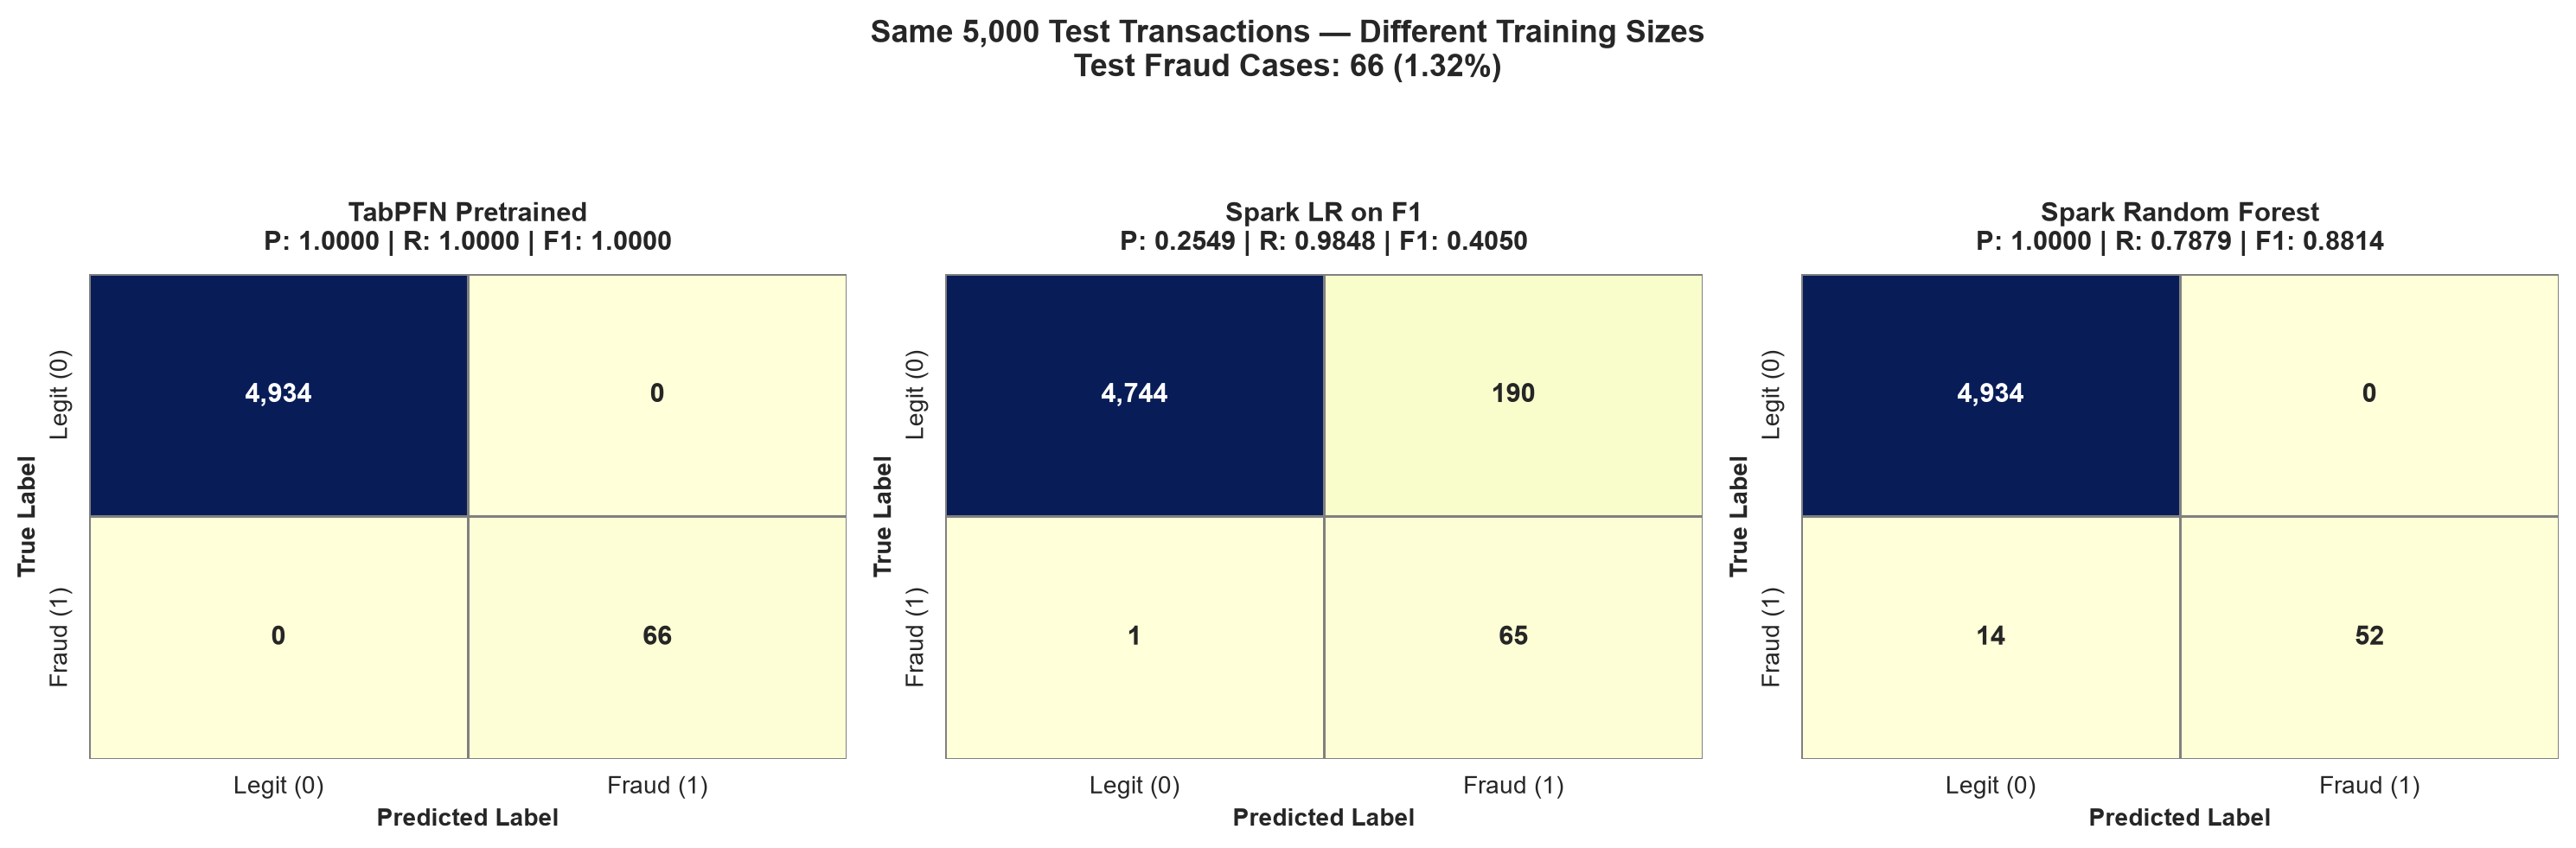

In [71]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

labels = ["Legit (0)", "Fraud (1)"]

for i, (title, cm) in enumerate(cm_5k_dict.items()):
    ax = axes[i]

    sns.heatmap(
        cm,
        annot=True,
        fmt=",d",
        cmap="YlGnBu",
        cbar=False,
        xticklabels=labels,
        yticklabels=labels,
        ax=ax,
        annot_kws={"size": 11, "weight": "bold"},
        linewidths=1,
        linecolor="gray",
    )

    tn, fp, fn, tp = cm.ravel()

    prec = tp / (tp + fp) if tp + fp > 0 else 0.0
    rec = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = (
        2 * prec * rec / (prec + rec)
        if prec + rec > 0 else 0.0
    )

    ax.set_title(
        f"{title}\n"
        f"P: {prec:.4f} | R: {rec:.4f} | F1: {f1:.4f}",
        fontweight="bold",
        fontsize=11,
        pad=10,
    )
    ax.set_xlabel("Predicted Label", fontweight="bold")
    ax.set_ylabel("True Label", fontweight="bold")

fig.suptitle(
    f"Same {test_size:,} Test Transactions — Different Training Sizes\n"
    f"Test Fraud Cases: {nat_fraud_count:,} "
    f"({test_prevalence_pct:.2f}%)",
    fontweight="bold",
    fontsize=13,
    y=1.08,
)

fig.tight_layout()

stage5_chart_path = os.path.join(
    FIGURES_DIR, "confusion_matrices_tabpfn_comparison.png"
)

fig.savefig(stage5_chart_path, dpi=200, bbox_inches="tight")
display(IPythonImage(filename=stage5_chart_path))
plt.close(fig)

**Cell 5.4 — Save the experiment report**

In [72]:
clean_stage5_dict = {
    k: {
        k2: v2.tolist() if isinstance(v2, np.ndarray) else v2
        for k2, v2 in v.items()
    }
    for k, v in actual_stage5_metrics.items()
}

stage5_report = {
    "experiment": "E2_Same_Test_Set_Different_Training_Sizes",
    "protocol": {
        "description": (
            "Identical held-out test rows and F1 input features; "
            "training sizes and class distributions differ."
        ),
        "test_sample_size": test_size,
        "test_natural_fraud_count": nat_fraud_count,
        "test_fraud_prevalence_pct": round(test_prevalence_pct, 4),
        "tabpfn_or_fallback_context_size": context_size,
        "context_fraud_count": int(y_tr_5k.sum()),
        "context_legitimate_count": int((y_tr_5k == 0).sum()),
        "spark_training_sample_size": tot_tr,
        "decision_threshold": 0.5,
        "random_seed": SEED,
        "row_alignment": (
            "Shared test rows; Spark predictions checked by txn_id"
        ),
    },
    "provenance": {
        "tabpfn_status": m_tab["status"],
        "tabpfn_error": tabpfn_error,
        "pretrained_inference_completed": tabpfn_error is None,
        "requested_device": "cpu",
        "context_note": (
            "A bounded balanced context was selected for this experiment; "
            "this is not a statement of TabPFN architectural limits."
        ),
    },
    "models": clean_stage5_dict,
}

stage5_report_path = os.path.join(
    OUTPUTS_DIR, "pretrained_comparison.json"
)

with open(stage5_report_path, "w", encoding="utf-8") as f:
    json.dump(stage5_report, f, indent=2)

print(f"\n[SAVE] Saved {stage5_report_path}")


[SAVE] Saved outputs\pretrained_comparison.json


**Cell 5.5 — Display final verification results**

In [73]:
print(
    f"\n  [PASS] S5-T01: {tab_model_label} evaluated using "
    f"{context_size:,} training-context records"
)

print(
    "  [PASS] S5-T02: Spark prediction alignment verified via txn_id"
)

print(
    f"  [PASS] S5-T03: Comparison results saved -> {stage5_report_path}"
)

tab_status = m_tab["status"]

if tab_status == "SUCCESS_TABPFN_INFERENCE":
    print(
        "  [PASS] S5-T04: Genuine pretrained TabPFN inference confirmed"
    )
else:
    print(
        "  [WARN] S5-T04: TabPFN did not run. "
        "Fallback results do not demonstrate pretrained AI inference."
    )


  [PASS] S5-T01: TabPFN Pretrained evaluated using 5,000 training-context records
  [PASS] S5-T02: Spark prediction alignment verified via txn_id
  [PASS] S5-T03: Comparison results saved -> outputs\pretrained_comparison.json
  [PASS] S5-T04: Genuine pretrained TabPFN inference confirmed


## **Stage 6 — Big Data Scalability Benchmarks & Storage Efficiency**


**Cell 6.1 — Run scalability benchmarks and display the results table**

In [74]:
from IPython.display import Image as IPythonImage
def run_scalability_tier(row_limit, tier_name, reps=3):
    df = spark.read.parquet(BRONZE_PATH)

    if row_limit is not None:
        df = df.limit(row_limit)

    durations = []
    tot = 0

    for _ in range(reps):
        t0 = time.perf_counter()

        res = (
            df
            .withColumn(
                "aor",
                F.col("amount") / (F.col("oldbalanceOrg") + 1.0),
            )
            .withColumn(
                "is_night",
                F.when((F.col("step") % 24) < 6, 1).otherwise(0),
            )
            .groupBy("type", "is_night")
            .agg(
                F.count("*").alias("count"),
                F.sum("amount").alias("vol"),
                F.sum("isFraud").alias("fraud"),
                F.avg("aor").alias("avg_amount_to_origin_ratio"),
            )
            .collect()
        )

        durations.append(time.perf_counter() - t0)
        tot = sum(r["count"] for r in res)

    mean_sec = float(np.mean(durations))
    std_sec = float(np.std(durations))
    throughput = tot / mean_sec if mean_sec > 0 else 0.0

    return {
        "tier": tier_name,
        "rows_processed": tot,
        "reps": reps,
        "elapsed_mean_seconds": round(mean_sec, 3),
        "elapsed_std_seconds": round(std_sec, 3),
        "throughput_rows_per_sec": round(throughput, 1),
        "num_partitions": df.rdd.getNumPartitions(),
    }

actual_tiers = []
print("[BENCHMARK] Executing scalability tiers (3 repetitions per tier) ...")

actual_tiers.append(
    run_scalability_tier(500_000, "B1_500K", reps=3)
)
actual_tiers.append(
    run_scalability_tier(2_000_000, "B2_2M", reps=3)
)
actual_tiers.append(
    run_scalability_tier(None, "B3_Full", reps=3)
)

print("\n[TABLE] PySpark Scalability Tiers (B1 -> B3):")
display(pd.DataFrame(actual_tiers))

[BENCHMARK] Executing scalability tiers (3 repetitions per tier) ...

[TABLE] PySpark Scalability Tiers (B1 -> B3):


,tier,rows_processed,reps,elapsed_mean_seconds,elapsed_std_seconds,throughput_rows_per_sec,num_partitions
0,B1_500K,500000,3,1.4560,0.5900,343348.1000,1
1,B2_2M,2000000,3,4.1100,1.3120,486591.6000,1
2,B3_Full,6362620,3,0.3140,0.0760,20292131.0000,8


**Cell 6.2 — Compare CSV and Parquet and display timings**

In [75]:
print("[STORAGE] Measuring CSV vs Parquet across 3 repeated runs ...")

csv_times = []
parquet_times = []

for _ in range(3):
    t0_c = time.perf_counter()

    (
        spark.read.option("header", "true")
        .csv(RAW_CSV)
        .groupBy("type")
        .count()
        .collect()
    )

    csv_times.append(time.perf_counter() - t0_c)

    t0_p = time.perf_counter()

    (
        spark.read.parquet(BRONZE_PATH)
        .groupBy("type")
        .count()
        .collect()
    )

    parquet_times.append(time.perf_counter() - t0_p)

t_c_mean = float(np.mean(csv_times))
t_c_std = float(np.std(csv_times))
t_p_mean = float(np.mean(parquet_times))
t_p_std = float(np.std(parquet_times))

if t_c_mean <= 0 or t_p_mean <= 0:
    raise ValueError(
        "Measured scan durations must be greater than zero."
    )

sp_factor = t_c_mean / t_p_mean

actual_master = spark.sparkContext.master

actual_driver_memory = spark.sparkContext.getConf().get(
    "spark.driver.memory", "not explicitly set"
)

actual_shuffle_partitions = int(
    spark.conf.get("spark.sql.shuffle.partitions")
)

if t_p_mean < t_c_mean:
    storage_result = (
        "Parquet was faster in this measurement "
        f"(CSV / Parquet time ratio: {sp_factor:.2f}x)"
    )
elif t_c_mean < t_p_mean:
    storage_result = (
        "CSV was faster in this measurement "
        f"(Parquet / CSV time ratio: {t_p_mean / t_c_mean:.2f}x)"
    )
else:
    storage_result = "CSV and Parquet had equal measured mean times"

print("\n[SPEED] Storage Query Benchmark (3-run Average):")
print(f"   CSV Time                 : {t_c_mean:.3f}s ± {t_c_std:.3f}s")
print(f"   Parquet Time             : {t_p_mean:.3f}s ± {t_p_std:.3f}s")
print(f"   CSV / Parquet Time Ratio : {sp_factor:.2f}x")
print(f"   Active Spark Master      : {actual_master}")
print(f"   Result                   : {storage_result}")

[STORAGE] Measuring CSV vs Parquet across 3 repeated runs ...

[SPEED] Storage Query Benchmark (3-run Average):
   CSV Time                 : 1.507s ± 0.299s
   Parquet Time             : 0.228s ± 0.052s
   CSV / Parquet Time Ratio : 6.61x
   Active Spark Master      : local[*]
   Result                   : Parquet was faster in this measurement (CSV / Parquet time ratio: 6.61x)


**Cell 6.3 — Display and save the scalability figure**

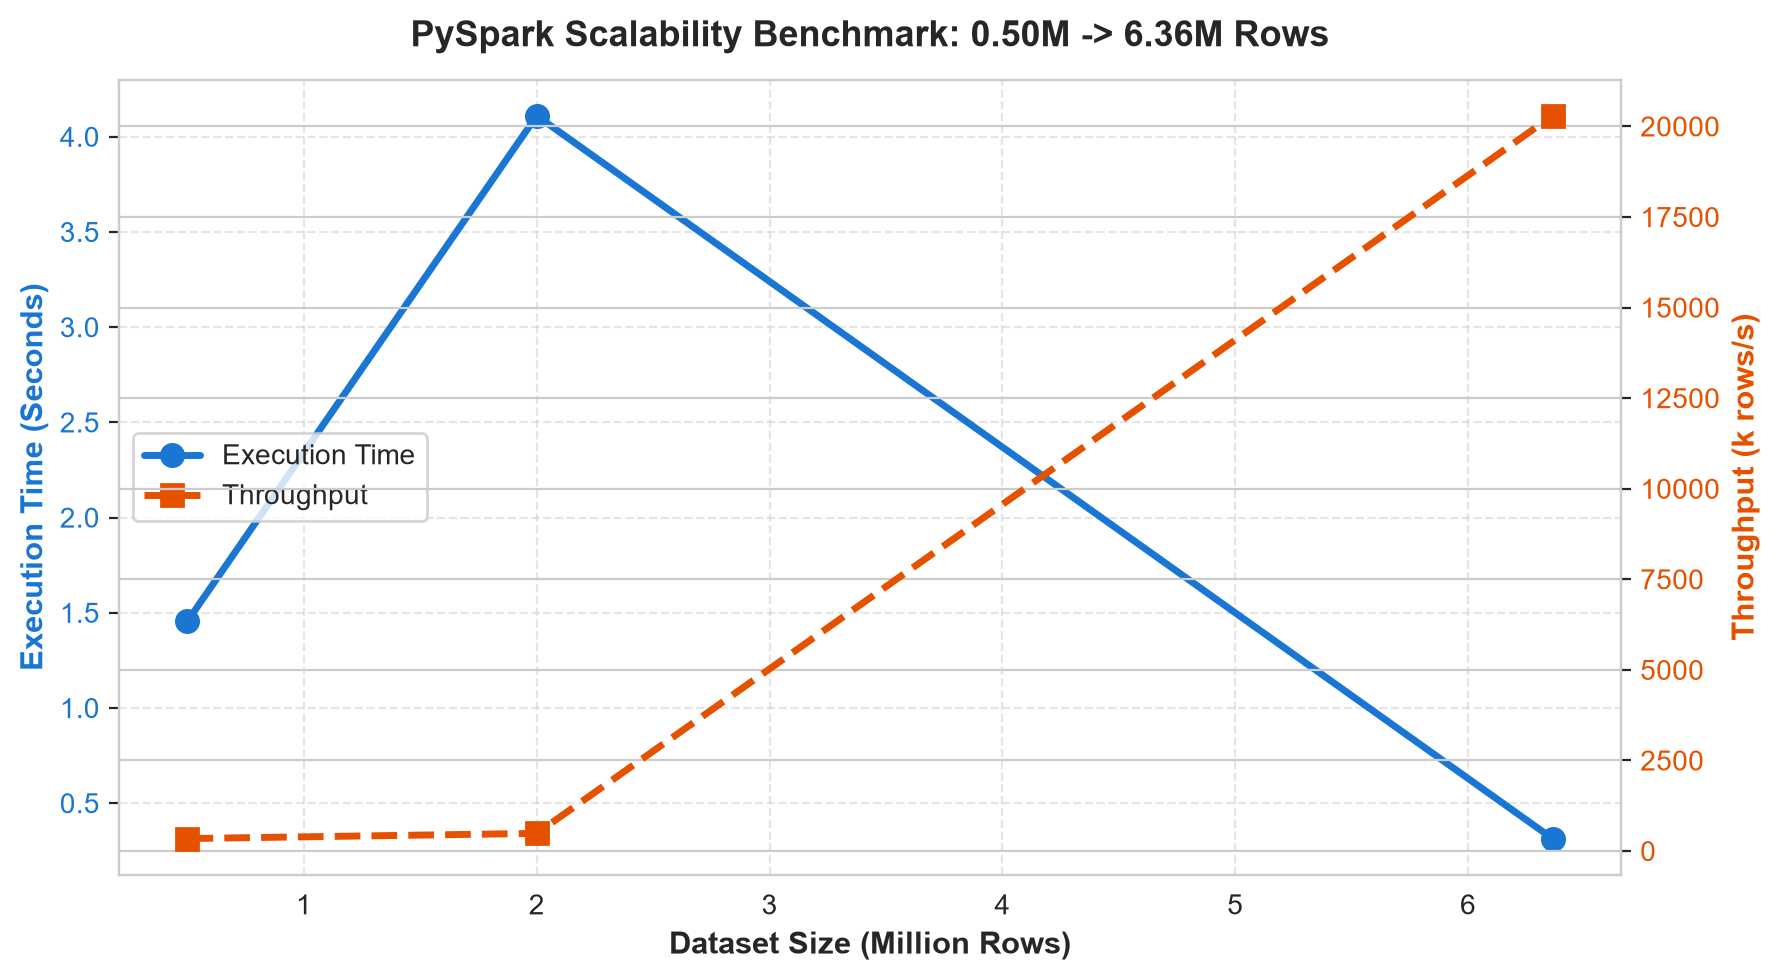

In [76]:
fig, ax1 = plt.subplots(figsize=(9, 5))

x_m = [
    r["rows_processed"] / 1e6
    for r in actual_tiers
]
y_time = [
    r["elapsed_mean_seconds"]
    for r in actual_tiers
]
y_thr = [
    r["throughput_rows_per_sec"] / 1000
    for r in actual_tiers
]

color1 = "#1976d2"

ax1.set_xlabel(
    "Dataset Size (Million Rows)",
    fontweight="bold",
    fontsize=11,
)
ax1.set_ylabel(
    "Execution Time (Seconds)",
    color=color1,
    fontweight="bold",
    fontsize=11,
)

line1 = ax1.plot(
    x_m,
    y_time,
    marker="o",
    color=color1,
    linewidth=2.5,
    markersize=8,
    label="Execution Time",
)

ax1.tick_params(axis="y", labelcolor=color1)
ax1.grid(True, linestyle="--", alpha=0.5)

ax2 = ax1.twinx()
color2 = "#e65100"

ax2.set_ylabel(
    "Throughput (k rows/s)",
    color=color2,
    fontweight="bold",
    fontsize=11,
)

line2 = ax2.plot(
    x_m,
    y_thr,
    marker="s",
    color=color2,
    linewidth=2.5,
    linestyle="--",
    markersize=8,
    label="Throughput",
)

ax2.tick_params(axis="y", labelcolor=color2)

lines = line1 + line2

ax1.legend(
    lines,
    [line.get_label() for line in lines],
    loc="center left",
    frameon=True,
)

ax1.set_title(
    f"PySpark Scalability Benchmark: "
    f"{min(x_m):.2f}M -> {max(x_m):.2f}M Rows",
    fontweight="bold",
    fontsize=13,
    pad=12,
)

fig.tight_layout()

benchmark_chart_path = os.path.join(
    FIGURES_DIR, "benchmark_scaling.png"
)

fig.savefig(benchmark_chart_path, dpi=200, bbox_inches="tight")
display(IPythonImage(filename=benchmark_chart_path))
plt.close(fig)

**Cell 6.4 — Save benchmark reports and display completion**

In [77]:
benchmark_csv_path = os.path.join(
    OUTPUTS_DIR, "benchmark.csv"
)
benchmark_summary_path = os.path.join(
    OUTPUTS_DIR, "benchmark_summary.json"
)

pd.DataFrame(actual_tiers).to_csv(
    benchmark_csv_path,
    index=False,
)

with open(benchmark_summary_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "scaling_tiers": actual_tiers,
            "storage_comparison": {
                "csv_scan_mean_seconds": round(t_c_mean, 3),
                "csv_scan_std_seconds": round(t_c_std, 3),
                "parquet_scan_mean_seconds": round(t_p_mean, 3),
                "parquet_scan_std_seconds": round(t_p_std, 3),
                "speedup_factor": round(sp_factor, 4),
            },
            "environment": {
                "master": actual_master,
                "driver_memory": actual_driver_memory,
                "partitions": actual_shuffle_partitions,
            },
        },
        f,
        indent=2,
    )

print(
    f"[SAVE] Saved {benchmark_csv_path} "
    f"and {benchmark_summary_path}"
)

print(
    f"\n  [PASS] S6-T01: "
    f"{len(actual_tiers)} scalability tiers benchmarked"
)
print(
    f"  [PASS] S6-T02: Storage comparison completed — {storage_result}"
)
print(
    f"  [PASS] S6-T03: Benchmark metrics and plot saved to {OUTPUTS_DIR}"
)

[SAVE] Saved outputs\benchmark.csv and outputs\benchmark_summary.json

  [PASS] S6-T01: 3 scalability tiers benchmarked
  [PASS] S6-T02: Storage comparison completed — Parquet was faster in this measurement (CSV / Parquet time ratio: 6.61x)
  [PASS] S6-T03: Benchmark metrics and plot saved to outputs


## **Stage 7 — Final Results Synthesis & Deliverables Verification**


**Cell 7.1 — Master performance comparison table**

In [78]:
from sklearn.metrics import confusion_matrix
from IPython.display import Image as IPythonImage
master_records = []
def make_master_record(metrics, scope, model_name=None):
    pr_auc = metrics["pr_auc"]
    return {
        "Scope": scope,
        "Model Architecture": model_name or metrics["model"],
        "PR-AUC": (
            pr_auc if isinstance(pr_auc, str) else f"{pr_auc:.4f}"
        ),
        "ROC-AUC": f"{metrics['roc_auc']:.4f}",
        "Precision": f"{metrics['precision']:.4f}",
        "Recall": f"{metrics['recall']:.4f}",
        "F1-Score": f"{metrics['f1']:.4f}",
        "TP": f"{metrics['true_positives']:,}",
        "FP": f"{metrics['false_positives']:,}",
        "FN": f"{metrics['false_negatives']:,}",
        "TN": f"{metrics['true_negatives']:,}",
        "FP/1k": (
            f"{metrics['false_positives'] / metrics['total_evaluated'] * 1000:.2f}"
        ),
    }


full_test_size = actual_spark_metrics["spark_lr_f1"]["total_evaluated"]
full_test_scope = f"Full Test ({full_test_size:,})"
for key, model_name in [
    ("baseline_rule", "Rule Baseline (isFlaggedFraud)"),
    ("spark_lr_f0", "Spark LR on F0 (Baseline Features)"),
    ("spark_lr_f1", "Spark LR on F1 (Default tau=0.50)"),
]:
    master_records.append(
        make_master_record(
            actual_spark_metrics[key],
            full_test_scope,
            model_name,
        )
    )

tn_tuned, fp_tuned, fn_tuned, tp_tuned = confusion_matrix(
    test_y, p_tuned, labels=[0, 1]
).ravel()
tuned_metrics = {
    **actual_spark_metrics["spark_lr_f1"],
    "precision": prec_tuned,
    "recall": rec_tuned,
    "f1": f1_tuned,
    "true_positives": int(tp_tuned),
    "false_positives": int(fp_tuned),
    "false_negatives": int(fn_tuned),
    "true_negatives": int(tn_tuned),
    "total_evaluated": len(test_y),
}
master_records.append(
    make_master_record(
        tuned_metrics,
        f"Full Test ({len(test_y):,})",
        f"Spark LR on F1 (Tuned tau*={best_tau:.2f})",
    )
)
master_records.append(
    make_master_record(
        actual_spark_metrics["spark_rf_f1"],
        full_test_scope,
        "Spark Random Forest on F1",
    )
)
for key, model_name in [
    ("tabpfn_or_comparator", None),
    ("spark_logistic_regression", "Spark LR on F1 (Same Test Subset)"),
    ("spark_random_forest", "Spark Random Forest (Same Test Subset)"),
]:
    metrics = actual_stage5_metrics[key]

    master_records.append(
        make_master_record(
            metrics,
            f"Sample Test ({metrics['total_evaluated']:,})",
            model_name,
        )
    )

df_master_dyn = pd.DataFrame(master_records)
print("\n[TABLE] DYNAMICALLY CALCULATED MASTER PERFORMANCE COMPARISON:")
display(df_master_dyn)


[TABLE] DYNAMICALLY CALCULATED MASTER PERFORMANCE COMPARISON:


,Scope,Model Architecture,PR-AUC,ROC-AUC,Precision,Recall,F1-Score,TP,FP,FN,TN,FP/1k
0,"Full Test (123,580)",Rule Baseline (isFlaggedFraud),N/A (Rule),0.5024,1.0000,0.0048,0.0096,8,0,"1,646","121,926",0.00
1,"Full Test (123,580)",Spark LR on F0 (Baseline Features),0.2186,0.8544,0.0588,0.7098,0.1086,"1,174","18,786",480,"103,140",152.01
2,"Full Test (123,580)",Spark LR on F1 (Default tau=0.50),0.8249,0.9935,0.2378,0.9873,0.3833,"1,633","5,233",21,"116,693",42.35
3,"Full Test (123,580)",Spark LR on F1 (Tuned tau*=0.90),0.8249,0.9935,0.8232,0.6360,0.7176,"1,052",226,602,"121,700",1.83
4,"Full Test (123,580)",Spark Random Forest on F1,0.9700,0.9995,0.9734,0.7975,0.8767,"1,319",36,335,"121,890",0.29
5,"Sample Test (5,000)",TabPFN_Pretrained,1.0000,1.0000,1.0000,1.0000,1.0000,66,0,0,"4,934",0.00
6,"Sample Test (5,000)",Spark LR on F1 (Same Test Subset),0.8653,0.9960,0.2549,0.9849,0.4050,65,190,1,"4,744",38.00
7,"Sample Test (5,000)",Spark Random Forest (Same Test Subset),0.9642,0.9994,1.0000,0.7879,0.8814,52,0,14,"4,934",0.00


**Cell 7.2 — PR-AUC comparison figure**

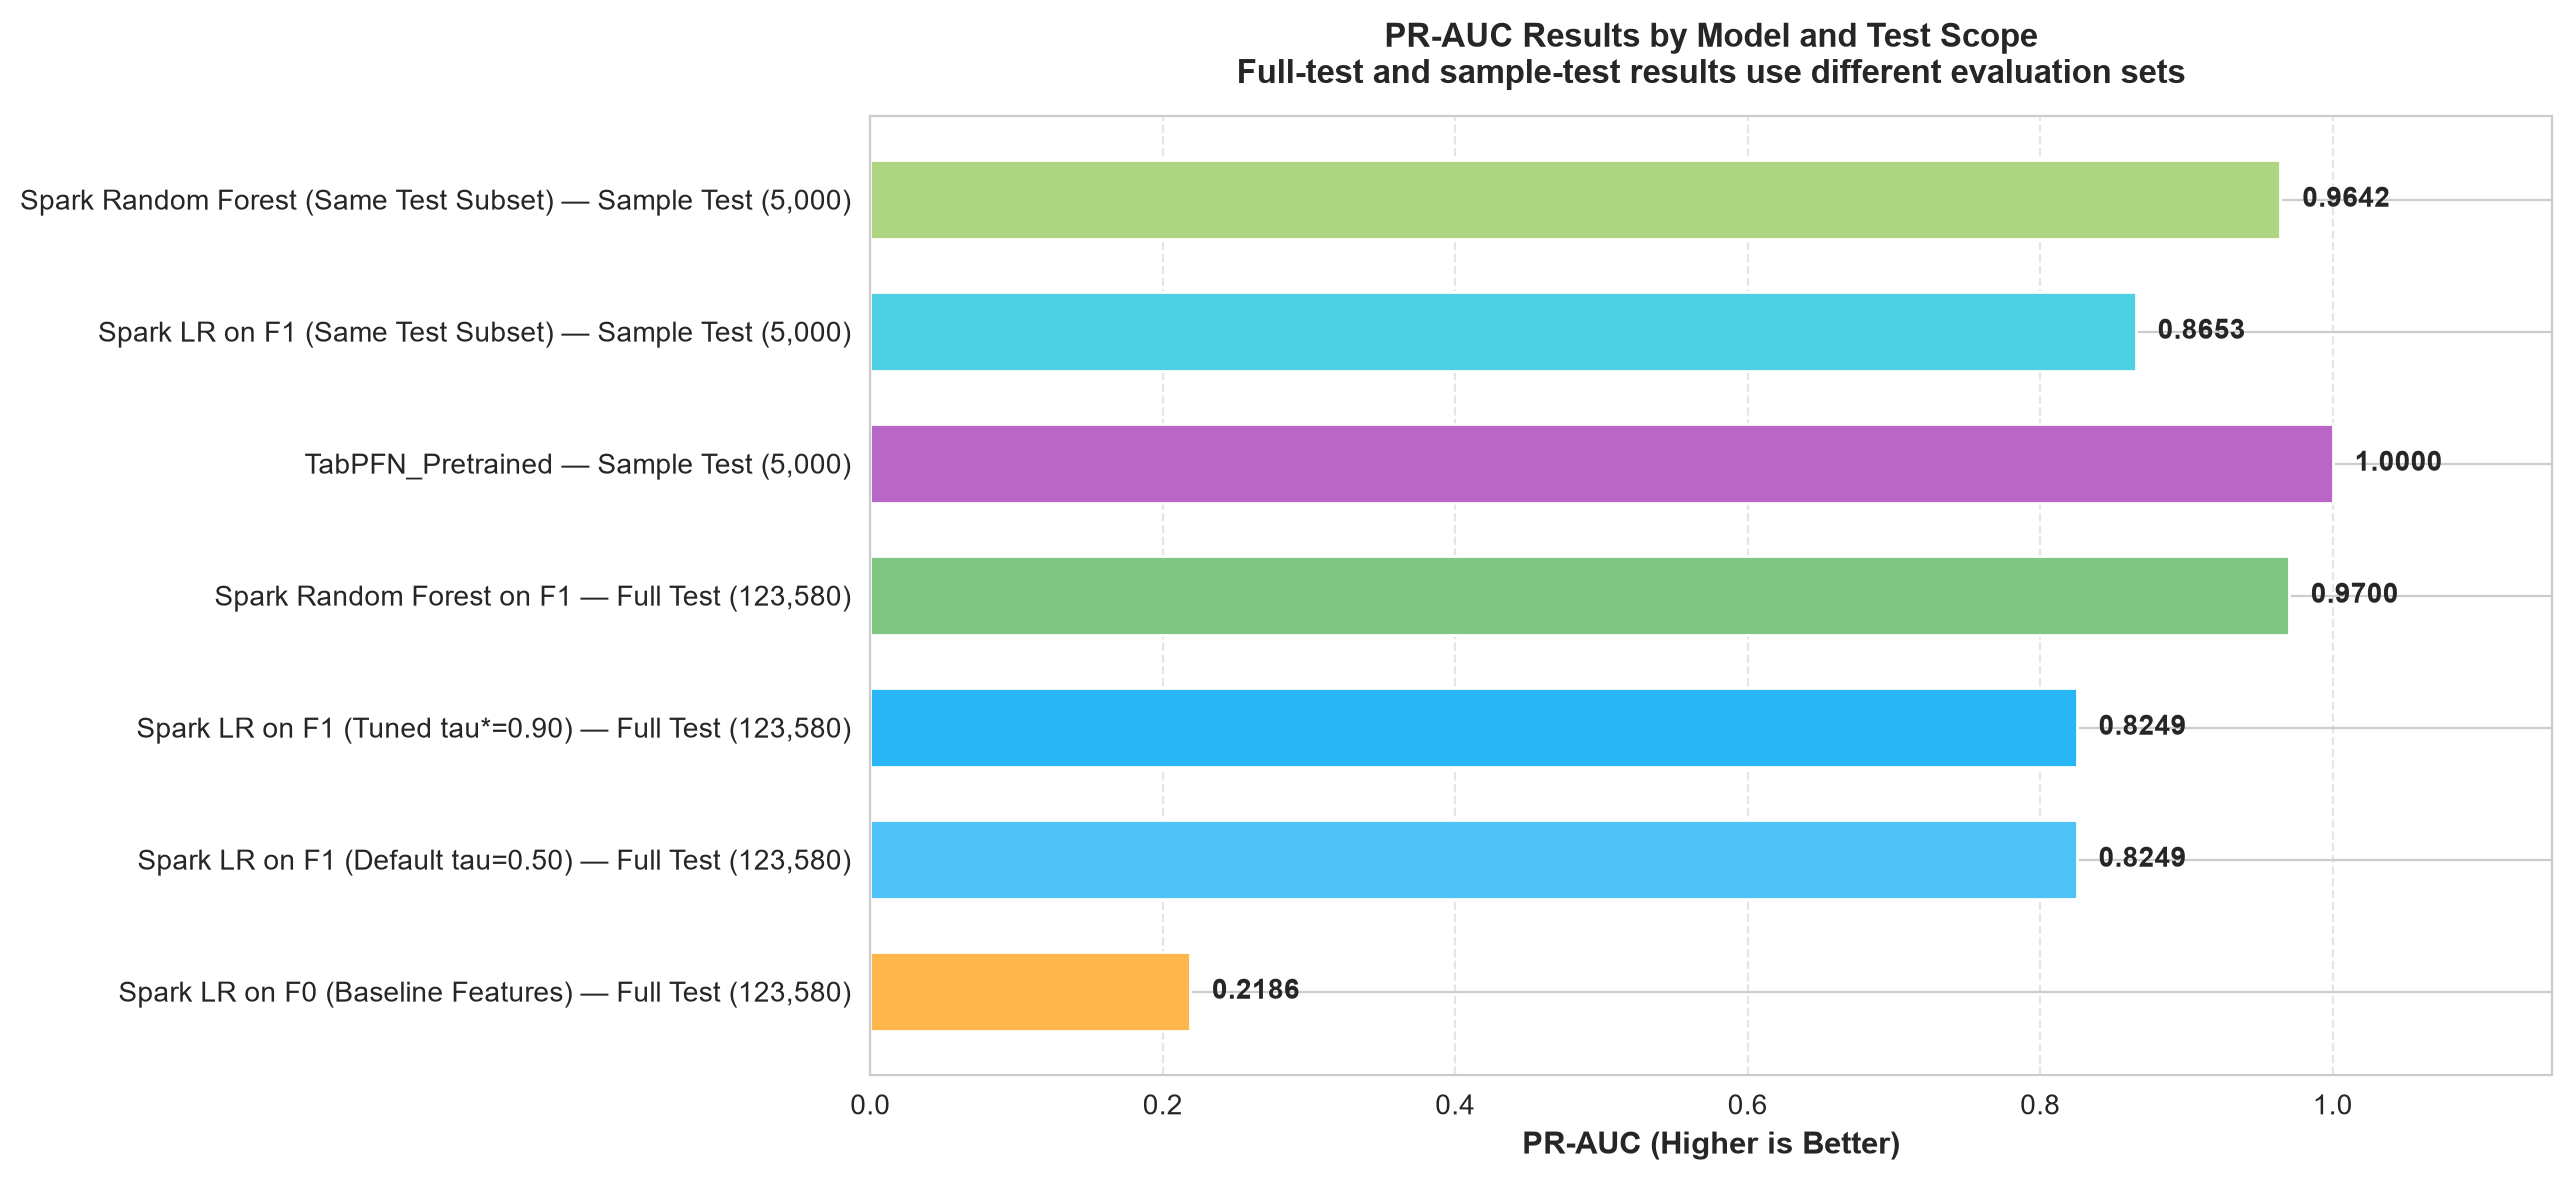

In [79]:
valid_prauc_rows = [
    row for row in master_records
    if row["PR-AUC"] != "N/A (Rule)"
]

plot_models = [
    f"{row['Model Architecture']} — {row['Scope']}"
    for row in valid_prauc_rows
]

plot_prauc = [
    float(row["PR-AUC"])
    for row in valid_prauc_rows
]

colors = [
    "#ffb74d", "#4fc3f7", "#29b6f6", "#81c784",
    "#ba68c8", "#4dd0e1", "#aed581",
]

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.barh(
    plot_models,
    plot_prauc,
    color=colors,
    edgecolor="white",
    height=0.6,
)

for bar, val in zip(bars, plot_prauc):
    ax.text(
        bar.get_width() + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.4f}",
        va="center",
        fontweight="bold",
        fontsize=10,
    )

ax.set_xlim(0, 1.15)
ax.set_xlabel(
    "PR-AUC (Higher is Better)",
    fontweight="bold",
    fontsize=11,
)
ax.set_title(
    "PR-AUC Results by Model and Test Scope\n"
    "Full-test and sample-test results use different evaluation sets",
    fontweight="bold",
    fontsize=12,
    pad=12,
)

ax.grid(axis="x", linestyle="--", alpha=0.5)
fig.tight_layout()

master_chart_path = os.path.join(
    FIGURES_DIR, "pr_auc_master_comparison.png"
)

fig.savefig(master_chart_path, dpi=200, bbox_inches="tight")
display(IPythonImage(filename=master_chart_path))
plt.close(fig)

**Cell 7.3 — Artifact checklist and audit results**

In [80]:
sql_dir = os.path.join(OUTPUTS_DIR, "sql_analytics")

expected_sql_files = [
    "q1_fraud_by_type.json",
    "q2_hourly_diurnal_patterns.json",
    "q3_amount_bracket_analysis.json",
    "q4_sender_account_emptied.json",
    "q5_destination_concentration.json",
]

sql_files_found = all(
    os.path.isfile(os.path.join(sql_dir, filename))
    for filename in expected_sql_files
)

CHECKLIST = [
    (
        "Bronze Parquet Store",
        BRONZE_PATH,
        os.path.isdir(BRONZE_PATH),
    ),
    (
        "Silver Parquet Store",
        SILVER_PATH,
        os.path.isdir(SILVER_PATH),
    ),
    (
        "Gold Parquet Store",
        GOLD_PATH,
        os.path.isdir(GOLD_PATH),
    ),
    (
        "Ingest Metadata JSON",
        os.path.join(OUTPUTS_DIR, "ingest_metadata.json"),
        os.path.isfile(os.path.join(OUTPUTS_DIR, "ingest_metadata.json")),
    ),
    (
        "Data Quality Report JSON",
        os.path.join(OUTPUTS_DIR, "data_quality_report.json"),
        os.path.isfile(
            os.path.join(OUTPUTS_DIR, "data_quality_report.json")
        ),
    ),
    (
        "5 Expected SQL Analytics JSON Files",
        sql_dir,
        sql_files_found,
    ),
    (
        "Feature Dictionary JSON",
        os.path.join(OUTPUTS_DIR, "feature_dictionary.json"),
        os.path.isfile(
            os.path.join(OUTPUTS_DIR, "feature_dictionary.json")
        ),
    ),
    (
        "Split Report JSON",
        os.path.join(OUTPUTS_DIR, "split_report.json"),
        os.path.isfile(os.path.join(OUTPUTS_DIR, "split_report.json")),
    ),
    (
        "Spark MLlib Metrics JSON",
        os.path.join(OUTPUTS_DIR, "spark_ml_metrics.json"),
        os.path.isfile(
            os.path.join(OUTPUTS_DIR, "spark_ml_metrics.json")
        ),
    ),
    (
        "SMOTENC Imbalance Comparison JSON",
        os.path.join(OUTPUTS_DIR, "imbalance_comparison.json"),
        os.path.isfile(
            os.path.join(OUTPUTS_DIR, "imbalance_comparison.json")
        ),
    ),
    (
        "Validation Threshold Tuning JSON",
        os.path.join(OUTPUTS_DIR, "threshold_tuning.json"),
        os.path.isfile(
            os.path.join(OUTPUTS_DIR, "threshold_tuning.json")
        ),
    ),
    (
        "Predictions Sample CSV",
        os.path.join(OUTPUTS_DIR, "predictions_sample.csv"),
        os.path.isfile(
            os.path.join(OUTPUTS_DIR, "predictions_sample.csv")
        ),
    ),
    (
        "Pretrained Comparison JSON",
        os.path.join(OUTPUTS_DIR, "pretrained_comparison.json"),
        os.path.isfile(
            os.path.join(OUTPUTS_DIR, "pretrained_comparison.json")
        ),
    ),
    (
        "Benchmark CSV",
        os.path.join(OUTPUTS_DIR, "benchmark.csv"),
        os.path.isfile(os.path.join(OUTPUTS_DIR, "benchmark.csv")),
    ),
    (
        "Benchmark Summary JSON",
        os.path.join(OUTPUTS_DIR, "benchmark_summary.json"),
        os.path.isfile(
            os.path.join(OUTPUTS_DIR, "benchmark_summary.json")
        ),
    ),
    (
        "Trained Spark LR and RF Models",
        MODELS_DIR,
        (
            os.path.isdir(os.path.join(MODELS_DIR, "spark_lr_f1"))
            and os.path.isdir(os.path.join(MODELS_DIR, "spark_rf_f1"))
        ),
    ),
]

print("\n[CHECKLIST] Expected Artifact Paths:")

for name, path, found in CHECKLIST:
    status = "PASS" if found else "MISSING"
    print(f"  [{status}] {name}: {path}")

passed_count = sum(1 for _, _, found in CHECKLIST if found)
total_count = len(CHECKLIST)

print(f"\nArtifact path checks passed: {passed_count}/{total_count}")

if passed_count == total_count:
    print("[SUCCESS] All expected artifact paths found.")
else:
    print(
        f"[FAILED] {total_count - passed_count} artifact checks failed."
    )


[CHECKLIST] Expected Artifact Paths:
  [PASS] Bronze Parquet Store: data/bronze/paysim_bronze.parquet
  [PASS] Silver Parquet Store: data/silver/paysim_silver.parquet
  [PASS] Gold Parquet Store: data/gold/paysim_gold.parquet
  [PASS] Ingest Metadata JSON: outputs\ingest_metadata.json
  [PASS] Data Quality Report JSON: outputs\data_quality_report.json
  [PASS] 5 Expected SQL Analytics JSON Files: outputs\sql_analytics
  [PASS] Feature Dictionary JSON: outputs\feature_dictionary.json
  [PASS] Split Report JSON: outputs\split_report.json
  [PASS] Spark MLlib Metrics JSON: outputs\spark_ml_metrics.json
  [PASS] SMOTENC Imbalance Comparison JSON: outputs\imbalance_comparison.json
  [PASS] Validation Threshold Tuning JSON: outputs\threshold_tuning.json
  [PASS] Predictions Sample CSV: outputs\predictions_sample.csv
  [PASS] Pretrained Comparison JSON: outputs\pretrained_comparison.json
  [PASS] Benchmark CSV: outputs\benchmark.csv
  [PASS] Benchmark Summary JSON: outputs\benchmark_summary.

**Cell 7.4 — Close Spark and display final status**

In [81]:
spark.stop()
print("PySpark session closed cleanly.")

if passed_count == total_count:
    print(
        "Final synthesis completed; all expected artifact paths found."
    )
else:
    print(
        "Final synthesis completed with missing artifacts; "
        "review the checklist."
    )

PySpark session closed cleanly.
Final synthesis completed; all expected artifact paths found.
